In [1]:
import numpy as np
import pandas as pd
import os
import random
import zipfile
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import (
    classification_report, 
    roc_auc_score, 
    ConfusionMatrixDisplay, 
    RocCurveDisplay,
    precision_recall_curve,
    f1_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from scipy.stats import loguniform, randint
import lightgbm as lgb
import catboost as cb
import shap
import joblib
from sklearn.preprocessing import LabelEncoder
import datetime
import optuna

c:\Users\amans\Desktop\LC FODS PROJECT\lendingclub\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
print("Downloading dataset from Kaggle...")
!kaggle datasets download -d wordsforthewise/lending-club
print("Download complete.")

Dataset URL: https://www.kaggle.com/datasets/wordsforthewise/lending-club
License(s): CC0-1.0
lending-club.zip: Skipping, found more recently modified local copy (use --force to force download)
Download complete.


In [3]:
import zipfile

# Define the path to your zip file
zip_file_path = 'lending-club.zip'

# Define the directory where you want to extract the files (e.g., ".")
extract_to_directory = 'dataset'

# Open and extract the zip file
with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_directory)

print(f"Successfully unzipped '{zip_file_path}' to '{extract_to_directory}'")

Successfully unzipped 'lending-club.zip' to 'dataset'


In [ ]:
# --- Load Data ---
# We load the full data, keep only MATURED + RESOLVED loans, then take the most recent 500k.
extract_dir = 'dataset'
csv_file_name = 'accepted_2007_to_2018Q4.csv.gz'
data_path = os.path.join(extract_dir, csv_file_name)

# Fraction of the loan term that must have elapsed by the data cutoff for a loan to be used.
# 1.0 = only fully matured cohorts. At 1.0, ~100% of eligible loans are resolved, so filtering
# to Fully Paid / Charged Off introduces no right-censoring bias. Lower values (e.g. 0.67)
# leave ~10% of loans still 'Current', which biases the default rate of the resolved subset.
MATURITY_FRACTION = 1.0

if os.path.exists(data_path):
    print("Loading full dataset to get most recent records...")
    # Only load necessary columns to save memory
    cols_to_load = ['loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'sub_grade',
                    'emp_length', 'home_ownership', 'annual_inc', 'verification_status',
                    'issue_d', 'loan_status', 'purpose', 'dti', 'delinq_2yrs', 
                    'earliest_cr_line', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 
                    'revol_util', 'total_acc', 'initial_list_status', 'application_type', 
                    'mort_acc', 'pub_rec_bankruptcies', 'tax_liens',
                    'recoveries', 'collection_recovery_fee'] # Load leaky feats to drop
    
    # Define dtypes for faster parsing
    dtype_dict = {
        'loan_amnt': 'float32', 'int_rate': 'float32', 'installment': 'float32',
        'annual_inc': 'float32', 'dti': 'float32', 'delinq_2yrs': 'float32',
        'inq_last_6mths': 'float32', 'open_acc': 'float32', 'pub_rec': 'float32',
        'revol_bal': 'float32', 'revol_util': 'float32', 'total_acc': 'float32',
        'mort_acc': 'float32', 'pub_rec_bankruptcies': 'float32', 'tax_liens': 'float32',
        'recoveries': 'float32', 'collection_recovery_fee': 'float32',
        'grade': 'category', 'sub_grade': 'category', 'home_ownership': 'category',
        'verification_status': 'category', 'purpose': 'category',
        'initial_list_status': 'category', 'application_type': 'category',
        'term': 'category', 'emp_length': 'category', 'loan_status': 'category'
    }
    df_full = pd.read_csv(data_path, 
                          usecols=cols_to_load,
                          dtype=dtype_dict,
                          parse_dates=['issue_d'], 
                          low_memory=False)
    
    print(f"Full dataset loaded with {len(df_full)} rows.")

    # --- 1. Fix Data Leakage ---
    # Drop features that are only known AFTER a default
    leaky_features = ['recoveries', 'collection_recovery_fee']
    df_full = df_full.drop(columns=leaky_features)
    print(f"Dropped leaky features: {leaky_features}")
    
    # --- 2. FIX (Issue 4): Filter to RESOLVED loans FIRST, then sample ---
    # Previously: took 500k most recent (mostly 'Current'), only ~57k survived after filtering.
    # Now: filter first, then take 500k resolved loans — yields ~500k usable records.
    good_status = [
        'Fully Paid', 
        'Does not meet the credit policy. Status:Fully Paid'
    ]
    bad_status = [
        'Charged Off', 
        'Default', 
        'Does not meet the credit policy. Status:Charged Off'
    ]
    resolved = good_status + bad_status

    # --- 2b. FIX (right-censoring): keep only MATURED loans BEFORE sampling ---
    # Previously the 500k most recent resolved loans ran up to late 2018. Recent loans that are
    # already 'resolved' are mostly early payoffs (charge-offs take months to surface), so the
    # most recent vintages had an artificially low default rate, and the test slice (newest 15%)
    # contained no seasoned loans at all. The cutoff is taken from the FULL dataset, not the sample.
    DATA_CUTOFF = df_full['issue_d'].max()
    full_term_months = df_full['term'].astype(str).str.extract(r'(\d+)')[0].astype(float)
    full_months_elapsed = (DATA_CUTOFF - df_full['issue_d']).dt.days / 30.44
    is_matured = full_months_elapsed >= full_term_months * MATURITY_FRACTION
    print(f"Data cutoff (latest issue_d in full file): {DATA_CUTOFF.date()}")
    print(f"Loans with >= {MATURITY_FRACTION:.0%} of term elapsed: {int(is_matured.sum())}")
    print(f"  of which resolved: {(is_matured & df_full['loan_status'].isin(resolved)).mean() / is_matured.mean():.1%}")
    
    df_resolved = df_full[is_matured & df_full['loan_status'].isin(resolved)].copy()
    print(f"Matured + resolved loans available: {len(df_resolved)}")
    
    # Create target variable
    status_map = {s: 0 for s in good_status}
    status_map.update({s: 1 for s in bad_status})
    df_resolved['is_default'] = df_resolved['loan_status'].map(status_map).astype(int)
    
    # Sort by date and take most recent 500k RESOLVED loans
    df_resolved = df_resolved.sort_values(by='issue_d', ascending=False)
    df_model = df_resolved.head(500000).copy()
    print(f"Final sample size: {len(df_model)}")
    print(f"Sample issue_d range: {df_model['issue_d'].min().date()} -> {df_model['issue_d'].max().date()}")
    
else:
    print(f"Error: Data file not found at {data_path}. Check extraction step.")

# --- Initial Data Inspection ---
print("\n--- Sample Data Loaded Successfully ---")
print(f"Shape of the loaded data: {df_model.shape}")
print(df_model.head())
print("\nDistribution of 'loan_status' in sample:")
print(df_model['loan_status'].value_counts())
print("\nDistribution of the binary target variable 'is_default':")
print(df_model['is_default'].value_counts())
print("\nPercentage distribution:")
print(df_model['is_default'].value_counts(normalize=True) * 100)


Starting EDA...


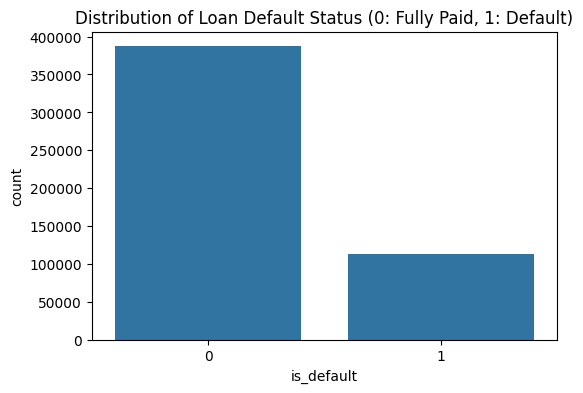

Overall Default Rate: 22.55%


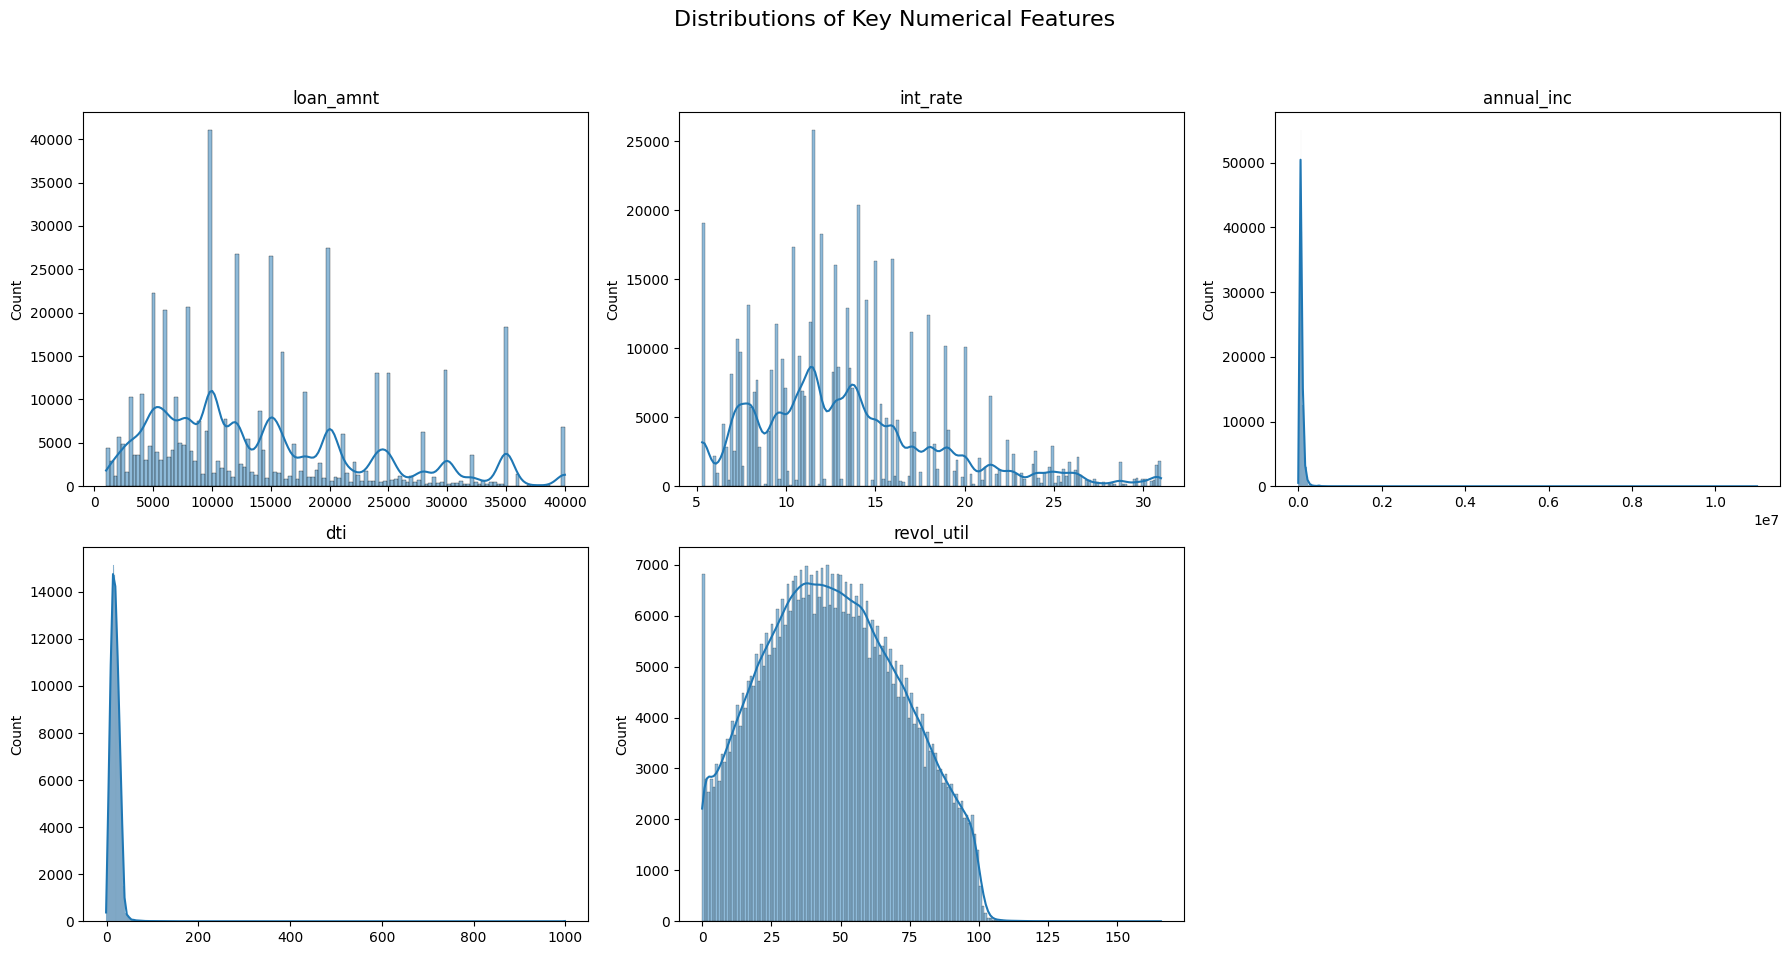

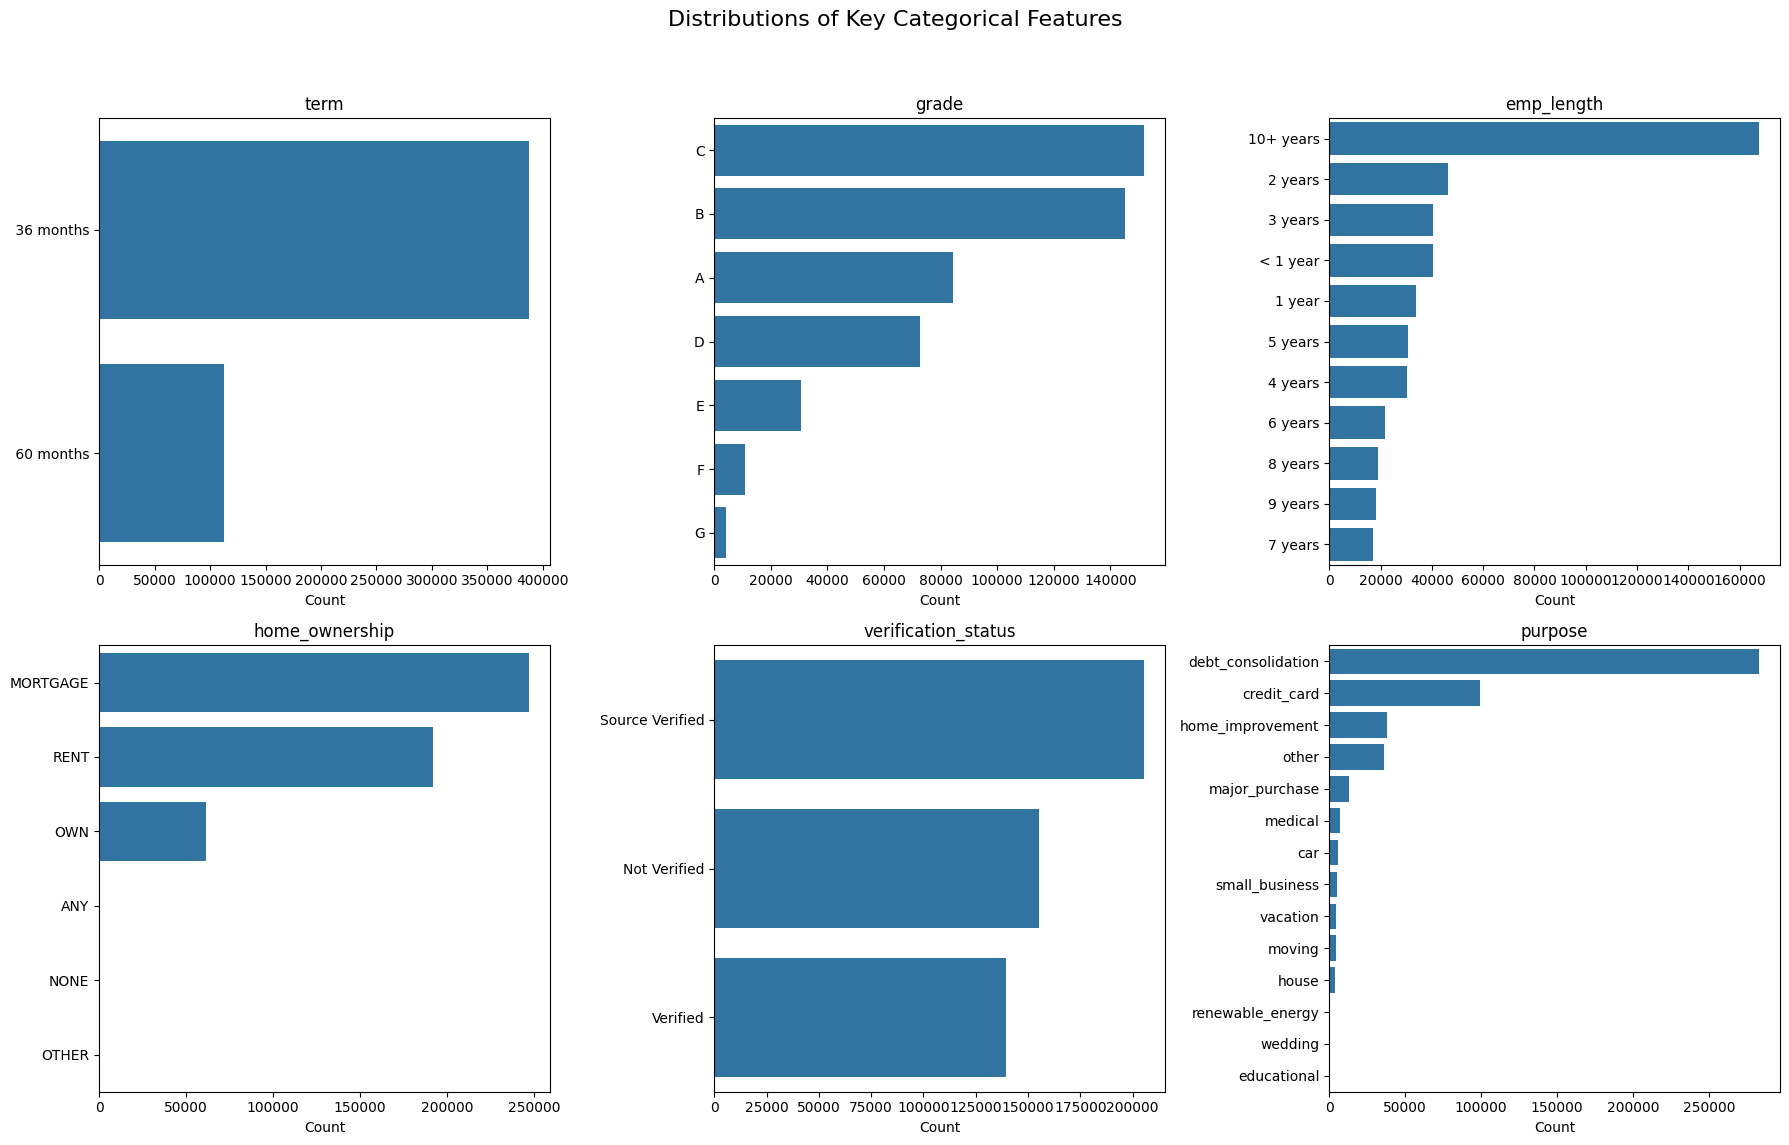

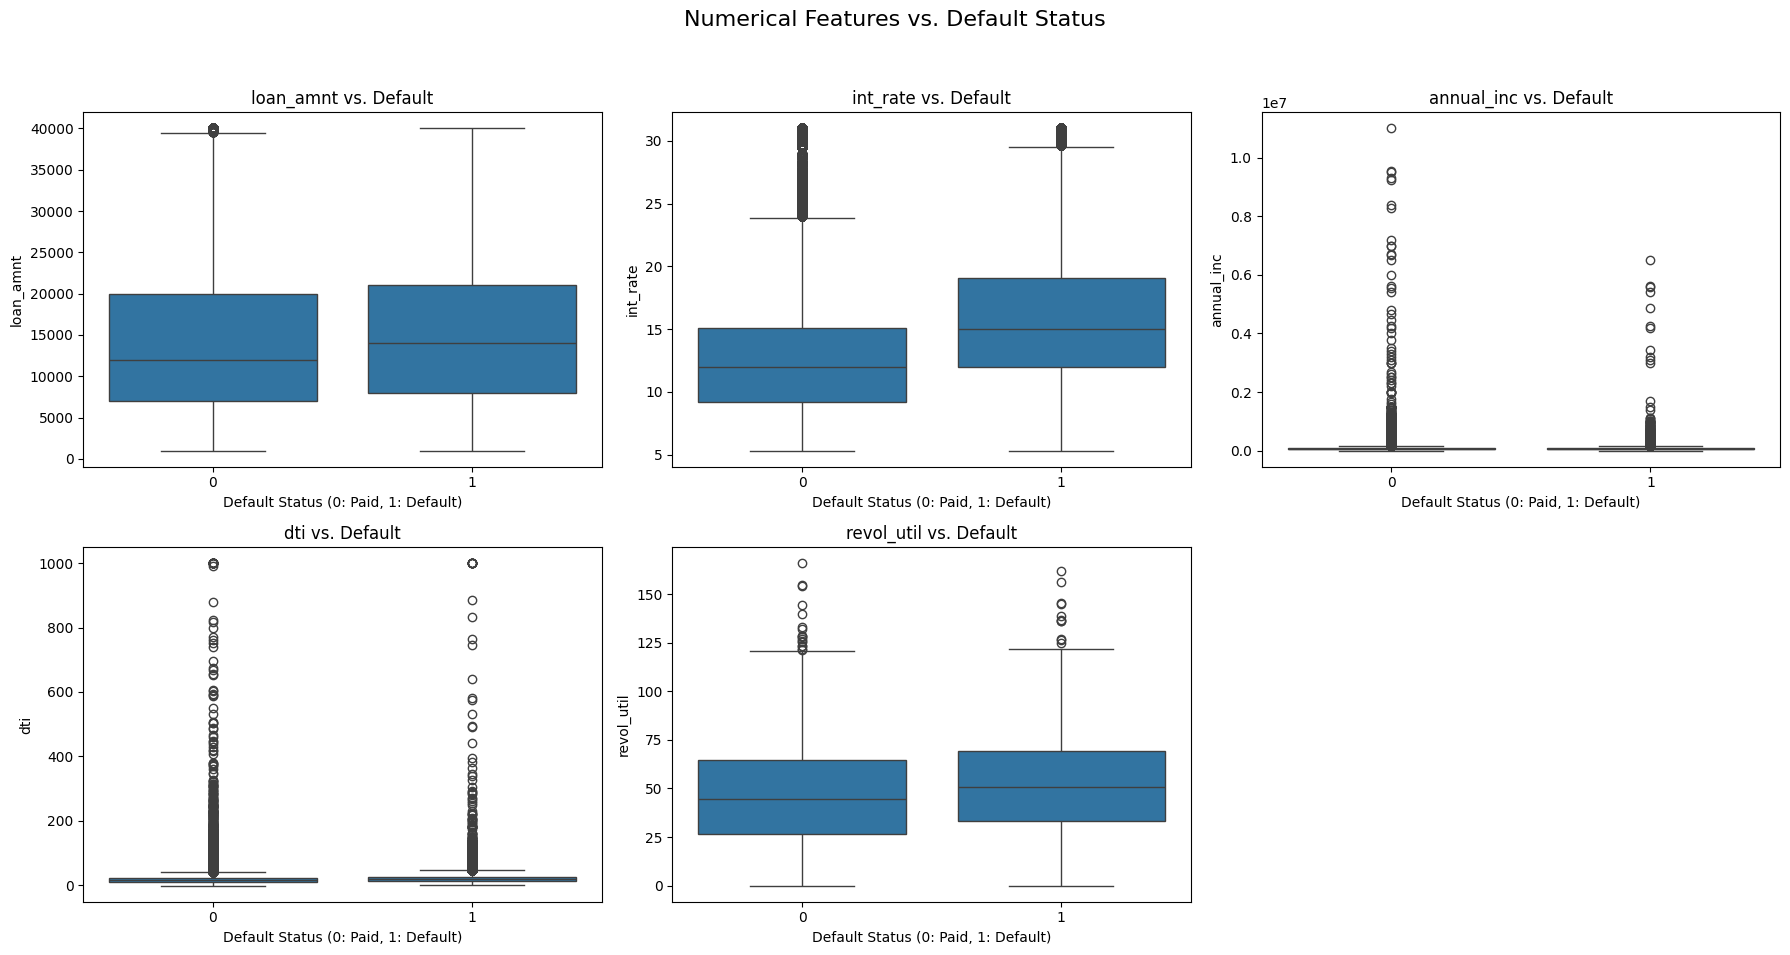

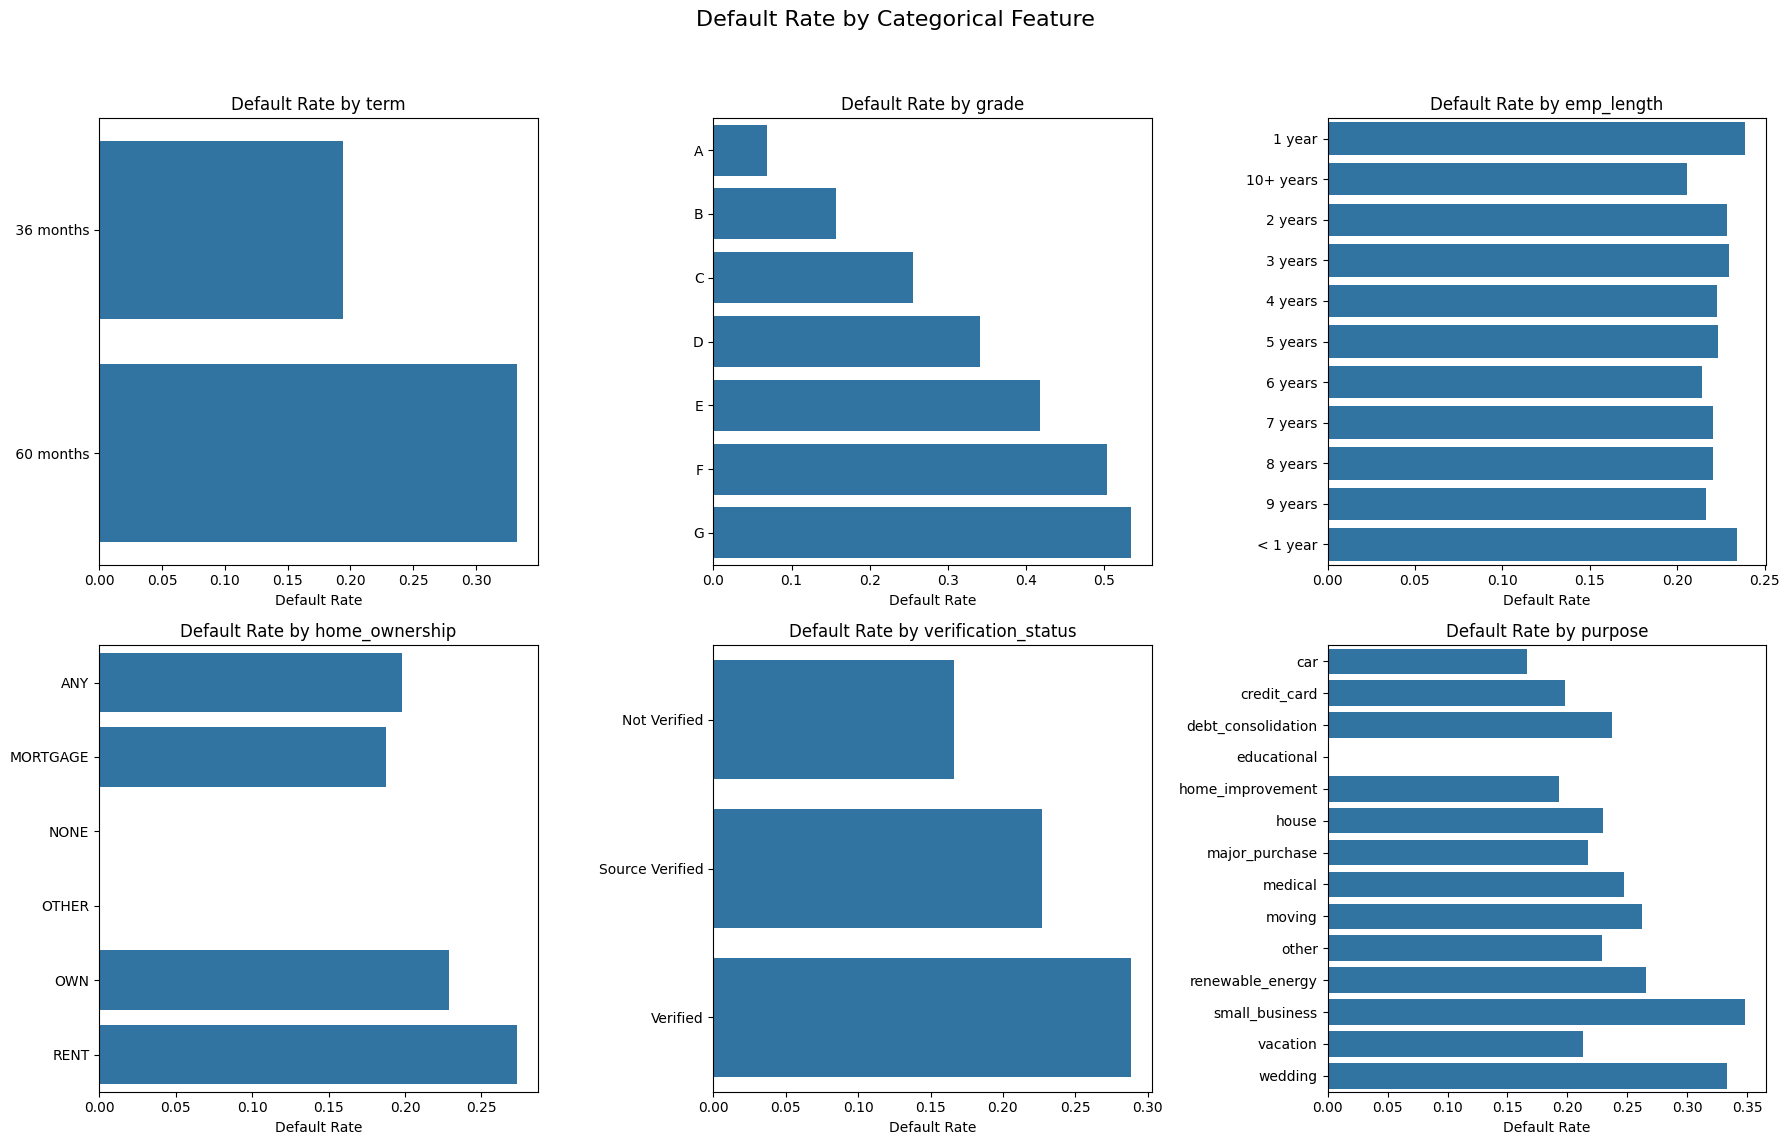


Correlation with is_default:
is_default              1.000000
int_rate                0.264696
revol_util              0.087031
inq_last_6mths          0.076167
installment             0.074174
loan_amnt               0.070291
dti                     0.066195
pub_rec                 0.026645
delinq_2yrs             0.024437
pub_rec_bankruptcies    0.021140
open_acc                0.014781
tax_liens               0.014476
revol_bal              -0.018108
total_acc              -0.030301
annual_inc             -0.044111
mort_acc               -0.097050
Name: is_default, dtype: float64


C:\Users\amans\AppData\Local\Temp\ipykernel_42316\707978727.py:79: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_corr.values, y=top_corr.index, palette='coolwarm')


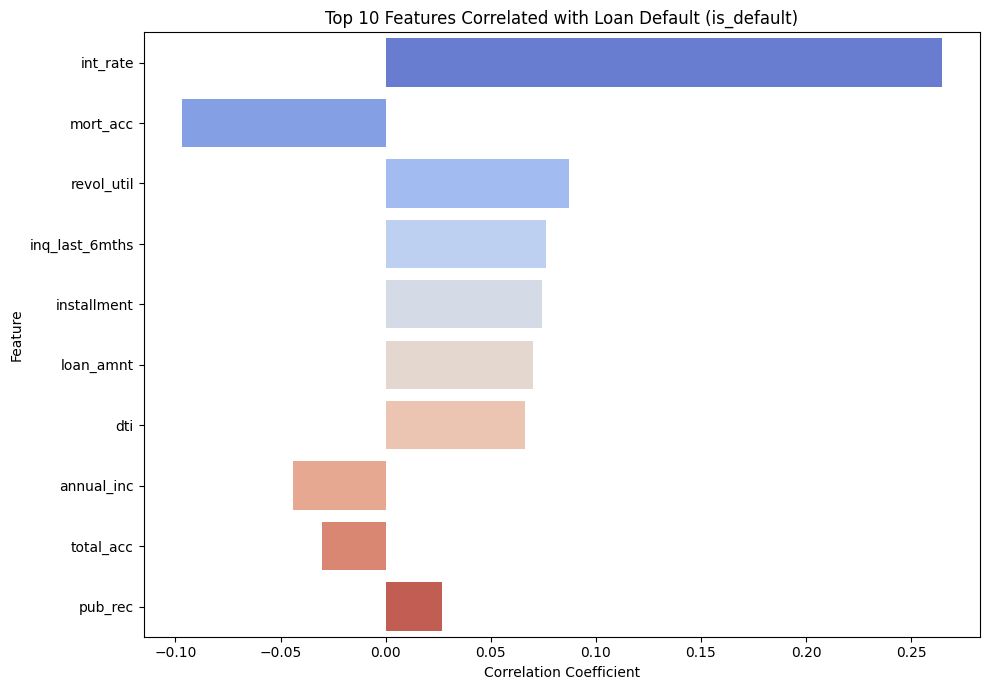

In [5]:
print("\nStarting EDA...")
plt.figure(figsize=(6, 4))
sns.countplot(x='is_default', data=df_model)
plt.title('Distribution of Loan Default Status (0: Fully Paid, 1: Default)')
plt.savefig('eda_target_distribution.png')
plt.show()

default_rate = df_model['is_default'].mean()
print(f"Overall Default Rate: {default_rate:.2%}")

# Numerical Features Univariate
numerical_to_plot = ['loan_amnt', 'int_rate', 'annual_inc', 'dti', 'revol_util']
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
fig.suptitle('Distributions of Key Numerical Features', fontsize=16)
axes = axes.flatten()

for i, col in enumerate(numerical_to_plot):
    sns.histplot(df_model[col].dropna(), kde=True, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel('')
fig.delaxes(axes[5])
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('eda_numerical_univariate.png')
plt.show()

# Categorical Features Univariate
categorical_to_plot = ['term', 'grade', 'emp_length', 'home_ownership', 'verification_status', 'purpose']
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 12))
fig.suptitle('Distributions of Key Categorical Features', fontsize=16)
axes = axes.flatten()

for i, col in enumerate(categorical_to_plot):
    order = df_model[col].value_counts().index
    sns.countplot(y=col, data=df_model, order=order, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel('Count')
    axes[i].set_ylabel('')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('eda_categorical_univariate.png')
plt.show()

# Bivariate (Numerical)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
fig.suptitle('Numerical Features vs. Default Status', fontsize=16)
axes = axes.flatten()
for i, col in enumerate(numerical_to_plot):
    sns.boxplot(x='is_default', y=col, data=df_model, ax=axes[i])
    axes[i].set_title(f'{col} vs. Default')
    axes[i].set_xlabel('Default Status (0: Paid, 1: Default)')
    axes[i].set_ylabel(col)
fig.delaxes(axes[5])
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('eda_numerical_bivariate.png')
plt.show()

# Bivariate (Categorical)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 12))
fig.suptitle('Default Rate by Categorical Feature', fontsize=16)
axes = axes.flatten()
for i, col in enumerate(categorical_to_plot):
    default_rates = df_model.groupby(col)['is_default'].mean().sort_values(ascending=False)
    sns.barplot(y=default_rates.index, x=default_rates.values, ax=axes[i], orient='h')
    axes[i].set_title(f'Default Rate by {col}')
    axes[i].set_xlabel('Default Rate')
    axes[i].set_ylabel('')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('eda_categorical_bivariate.png')
plt.show()

# Correlation
numerical_cols_for_corr = df_model.select_dtypes(include=np.number).columns.tolist()
correlation_matrix = df_model[numerical_cols_for_corr].corr()
corr_with_target = correlation_matrix['is_default'].sort_values(ascending=False)
print("\nCorrelation with is_default:")
print(corr_with_target)

plt.figure(figsize=(10, 7))
top_corr = corr_with_target.drop('is_default').sort_values(key=abs, ascending=False).head(10)
sns.barplot(x=top_corr.values, y=top_corr.index, palette='coolwarm')
plt.title('Top 10 Features Correlated with Loan Default (is_default)')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Feature')
plt.tight_layout()
plt.savefig('eda_top_10_correlation.png')
plt.show()

Starting feature engineering...
Feature Engineering complete.


C:\Users\amans\AppData\Local\Temp\ipykernel_42316\2939885838.py:13: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_processed['earliest_cr_line'] = pd.to_datetime(df_processed['earliest_cr_line'], errors='coerce')


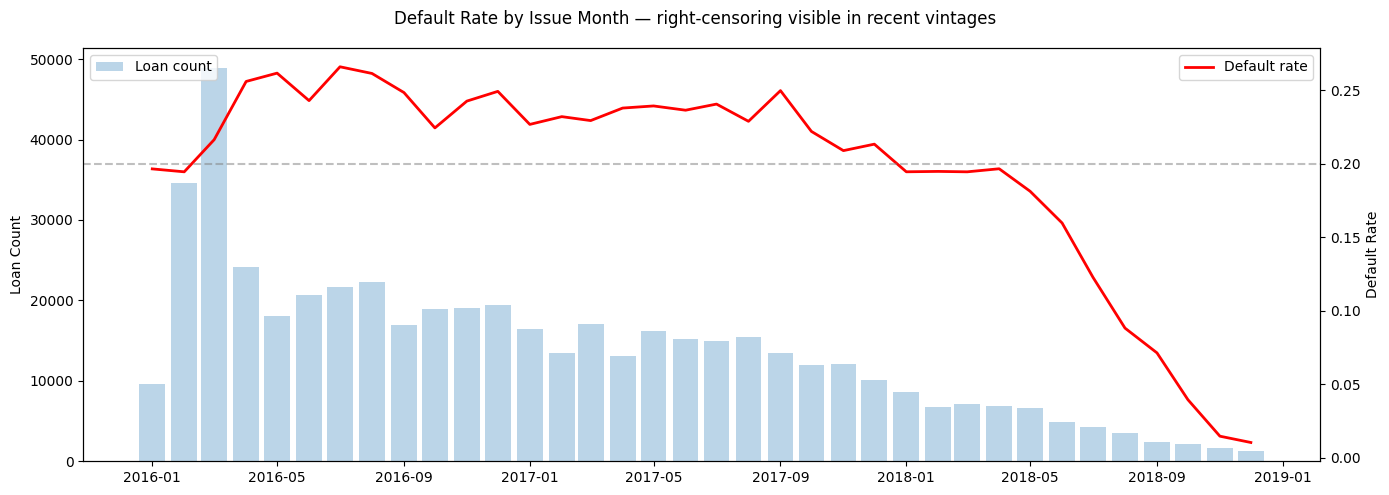


The drop in default rate for recent months is right-censoring:
loans issued near the end of the window haven't had time to charge off.

Dataset ends at: 2018-12-01 00:00:00

Seasoning filter: keep loans with >= 67% of term elapsed
X_train: (350000, 33), X_val: (75000, 33)
X_test (before filter): (75000, 33)
X_test (after filter):  (0, 33)  (75000 unseasoned loans removed)

  This means the test default rate is optimistically biased by right-censoring.

Train default rate: 0.2352
Val default rate:   0.2342
Test default rate:  0.1712

Identified 25 numerical features for scaling.
Identified 8 categorical features for OHE.

Fitting preprocessor and transforming X_train (for LR/RF/DT)...
Transforming X_val and X_test (for LR/RF/DT)...

Preparing data for LightGBM/CatBoost (Leak-Free)...
X_train_gb, X_val_gb, and X_test_gb prepared for LightGBM/CatBoost.
Categorical features for boost: ['term', 'sub_grade', 'emp_length', 'home_ownership', 'verification_status', 'purpose', 'initial_list_sta

In [6]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

print("Starting feature engineering...")
df_processed = df_model.copy()

# === 1. Feature Engineering ===
df_processed['income_to_loan_ratio'] = df_processed['annual_inc'] / (df_processed['loan_amnt'] + 1)
df_processed['credit_utilization_ratio'] = df_processed['revol_bal'] / (df_processed['total_acc'] + 1)

df_processed['earliest_cr_line'] = pd.to_datetime(df_processed['earliest_cr_line'], errors='coerce')
df_processed['credit_history_days'] = (df_processed['issue_d'] - df_processed['earliest_cr_line']).dt.days

df_processed['term_in_months'] = df_processed['term'].str.replace(' months', '').astype(float)
df_processed['total_payment'] = df_processed['term_in_months'] * df_processed['installment']
df_processed['payment_to_income_ratio'] = df_processed['installment'] / (df_processed['annual_inc'] + 1)
df_processed['open_acc_to_total_acc'] = df_processed['open_acc'] / (df_processed['total_acc'] + 1)

df_processed['util_x_dti'] = df_processed['revol_util'].fillna(0) * df_processed['dti'].fillna(0)

# Interaction features
df_processed['rate_x_dti'] = df_processed['int_rate'] * df_processed['dti'].fillna(0)
df_processed['installment_to_loan'] = df_processed['installment'] / (df_processed['loan_amnt'] + 1)

print("Feature Engineering complete.")

# === 2. Feature Selection ===
features_to_keep = [
    'loan_amnt', 'term', 'int_rate', 'installment', 'sub_grade',
    'emp_length', 'home_ownership', 'annual_inc', 'verification_status',
    'purpose', 'dti', 'delinq_2yrs', 'inq_last_6mths', 'open_acc', 
    'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 
    'application_type', 'mort_acc', 'pub_rec_bankruptcies', 'tax_liens', 
    'income_to_loan_ratio', 'credit_utilization_ratio', 'credit_history_days', 
    'term_in_months', 'total_payment', 
    'payment_to_income_ratio', 'open_acc_to_total_acc', 'util_x_dti',
    'rate_x_dti', 'installment_to_loan',
    'is_default', 'issue_d' 
]

df_processed = df_processed[features_to_keep].copy()
df_processed.replace([np.inf, -np.inf], np.nan, inplace=True)

# === 2b. Diagnose base-rate shift ===
monthly = df_processed.groupby(df_processed['issue_d'].dt.to_period('M'))['is_default'].agg(['mean', 'count'])
monthly.index = monthly.index.to_timestamp()

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.bar(monthly.index, monthly['count'], width=25, alpha=0.3, label='Loan count')
ax1.set_ylabel('Loan Count')
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly['mean'], color='red', linewidth=2, label='Default rate')
ax2.set_ylabel('Default Rate')
ax2.axhline(y=0.20, color='gray', linestyle='--', alpha=0.5)
fig.suptitle('Default Rate by Issue Month — right-censoring visible in recent vintages')
ax1.legend(loc='upper left'); ax2.legend(loc='upper right')
plt.tight_layout()
plt.savefig('base_rate_shift_diagnosis.png')
plt.show()

print("\nThe drop in default rate for recent months is right-censoring:")
print("loans issued near the end of the window haven't had time to charge off.")

# === 3. Data Splitting (70/15/15 temporal) with seasoning filter ===
df_processed = df_processed.sort_values(by='issue_d')
df_processed['term_in_months'] = df_processed['term'].str.replace(' months', '').astype(float)

# Use the cutoff of the FULL dataset (set in the load cell), not the sample's latest issue_d.
# The sample is already restricted to matured loans, so this is a sanity check that should keep
# every test row.
data_cutoff = DATA_CUTOFF
print(f"\nDataset ends at: {data_cutoff}")

SEASONING_FRACTION = MATURITY_FRACTION
df_processed['months_elapsed'] = (
    (data_cutoff - df_processed['issue_d']).dt.days / 30.44
)
df_processed['is_seasoned'] = df_processed['months_elapsed'] >= (
    df_processed['term_in_months'] * SEASONING_FRACTION
)

X = df_processed.drop(['is_default', 'issue_d', 'months_elapsed', 'is_seasoned'], axis=1)
y = df_processed['is_default']

n = len(df_processed)
train_end = int(0.70 * n)
val_end = int(0.85 * n)

X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]

# Test set: only seasoned loans
test_slice = df_processed.iloc[val_end:]
test_mask = test_slice['is_seasoned'].values
X_test_full = X.iloc[val_end:]
y_test_full = y.iloc[val_end:]
X_test = X_test_full[test_mask]
y_test = y_test_full[test_mask]

n_dropped = int((~test_slice['is_seasoned']).sum())
print(f"\nSeasoning filter: keep loans with >= {SEASONING_FRACTION:.0%} of term elapsed")
print(f"X_train: {X_train.shape}, X_val: {X_val.shape}")
print(f"X_test (before filter): {X_test_full.shape}")
print(f"X_test (after filter):  {X_test.shape}  ({n_dropped} unseasoned loans removed)")

# Fail loudly instead of silently evaluating on a right-censored test set.
assert len(X_test) > 0, (
    "Seasoning filter removed all test rows. Re-run the load cell so df_model "
    "contains only matured loans."
)
if n_dropped > 0:
    print(f"\nNOTE: {n_dropped} unseasoned test loans were dropped (expected 0).")

print(f"\nTrain default rate: {y_train.mean():.4f}")
print(f"Val default rate:   {y_val.mean():.4f}")
print(f"Test default rate:  {y_test.mean():.4f}")
if n_dropped > 0 and len(X_test) < len(X_test_full):
    print(f"Test default rate (unfiltered): {y_test_full.mean():.4f}")

# === 4. Preprocessing for LR / DT / RF (Pipeline) ===
categorical_features_ohe = [
    'term', 'sub_grade', 'emp_length', 'home_ownership', 
    'verification_status', 'purpose', 'initial_list_status', 
    'application_type'
]
numerical_features = [col for col in X_train.columns if col not in categorical_features_ohe]

print(f"\nIdentified {len(numerical_features)} numerical features for scaling.")
print(f"Identified {len(categorical_features_ohe)} categorical features for OHE.")

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=True))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features_ohe)
    ],
    remainder='passthrough'
)

print("\nFitting preprocessor and transforming X_train (for LR/RF/DT)...")
X_train_processed = preprocessor.fit_transform(X_train)

print("Transforming X_val and X_test (for LR/RF/DT)...")
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# === 5. Preprocessing for LGBM / CatBoost (Leak-Free) ===
print("\nPreparing data for LightGBM/CatBoost (Leak-Free)...")
X_train_gb = X_train.copy()
X_val_gb = X_val.copy()
X_test_gb = X_test.copy()

categorical_features_for_boost = [
    'term', 'sub_grade', 'emp_length', 'home_ownership', 
    'verification_status', 'purpose', 'initial_list_status', 
    'application_type'
]

imputation_values = {}
label_encoders = {}

for col in X_train_gb.columns:
    if col in categorical_features_for_boost:
        mode_val = X_train_gb[col].mode()[0]
        imputation_values[col] = mode_val
        X_train_gb[col] = X_train_gb[col].fillna(mode_val).astype(str)
        X_val_gb[col] = X_val_gb[col].fillna(mode_val).astype(str)
        X_test_gb[col] = X_test_gb[col].fillna(mode_val).astype(str)
        
        le = LabelEncoder()
        le.fit(X_train_gb[col]) 
        X_train_gb[col] = le.transform(X_train_gb[col])
        X_val_gb[col] = X_val_gb[col].map(lambda s, _le=le: _le.transform([s])[0] if s in _le.classes_ else -1)
        X_test_gb[col] = X_test_gb[col].map(lambda s, _le=le: _le.transform([s])[0] if s in _le.classes_ else -1)
        label_encoders[col] = le
        
    elif col in numerical_features:
        median_val = X_train_gb[col].median()
        imputation_values[col] = median_val
        X_train_gb[col] = X_train_gb[col].fillna(median_val)
        X_val_gb[col] = X_val_gb[col].fillna(median_val)
        X_test_gb[col] = X_test_gb[col].fillna(median_val)

for col in categorical_features_for_boost:
    X_train_gb[col] = X_train_gb[col].astype('int32')
    X_val_gb[col] = X_val_gb[col].astype('int32')
    X_test_gb[col] = X_test_gb[col].astype('int32')
        
print("X_train_gb, X_val_gb, and X_test_gb prepared for LightGBM/CatBoost.")
print(f"Categorical features for boost: {categorical_features_for_boost}")

In [7]:
# --- 6. Model Training ---

from sklearn.metrics import (
    classification_report, roc_auc_score, ConfusionMatrixDisplay,
    RocCurveDisplay, precision_recall_curve, f1_score,
    average_precision_score, brier_score_loss
)
from scipy.stats import ks_2samp

# Evaluation Function — now returns metrics dict for the comparison table
def evaluate_model(model, X_test_data, y_test_data, model_name):
    print(f"\n--- Evaluation Report for: {model_name} ---")
    
    y_pred = model.predict(X_test_data)
    y_pred_proba = model.predict_proba(X_test_data)[:, 1]
        
    test_auc = roc_auc_score(y_test_data, y_pred_proba)
    pr_auc = average_precision_score(y_test_data, y_pred_proba)
    brier = brier_score_loss(y_test_data, y_pred_proba)
    ks_stat = ks_2samp(
        y_pred_proba[y_test_data == 1],
        y_pred_proba[y_test_data == 0]
    ).statistic

    print(f"Test ROC-AUC: {test_auc:.4f}")
    print(f"Test PR-AUC:  {pr_auc:.4f}  (baseline: {y_test_data.mean():.4f})")
    print(f"Brier Score:  {brier:.4f}")
    print(f"KS Statistic: {ks_stat:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test_data, y_pred, target_names=['Fully Paid (0)', 'Default (1)']))
    
    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    ConfusionMatrixDisplay.from_estimator(model, X_test_data, y_test_data, 
                                          cmap='Blues', 
                                          display_labels=['Fully Paid', 'Default'],
                                          ax=ax[0])
    ax[0].set_title(f"{model_name} - Confusion Matrix")
    RocCurveDisplay.from_estimator(model, X_test_data, y_test_data, ax=ax[1])
    ax[1].plot([0, 1], [0, 1], color='red', linestyle='--')
    ax[1].set_title(f"{model_name} - ROC Curve")
    plt.tight_layout()
    plt.savefig(f'evaluation_{model_name.replace(" ", "_")}.png')
    plt.show()

    return {
        'Model': model_name,
        'ROC-AUC': round(test_auc, 4),
        'PR-AUC': round(pr_auc, 4),
        'Brier': round(brier, 4),
        'KS': round(ks_stat, 4),
    }

# Collect metrics for the consolidated comparison table
all_metrics = []

In [8]:
# --- Model 1: Logistic Regression ---
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)

# l1_ratio=0 is equivalent to penalty='l2' but avoids the FutureWarning
# (penalty param is deprecated in sklearn 1.8, removed in 1.10)
model_lr = LogisticRegression(
    l1_ratio=0, solver='lbfgs', class_weight='balanced', 
    random_state=42, max_iter=1000
)
param_dist_lr = {'C': loguniform(0.001, 100)}
random_search_lr = RandomizedSearchCV(
    model_lr, param_dist_lr, n_iter=10, cv=tscv, 
    scoring='roc_auc', n_jobs=-1, random_state=42
)
print("\nStarting RandomizedSearchCV for Logistic Regression (TimeSeriesSplit)...")
random_search_lr.fit(X_train_processed, y_train)
print("Search complete.")
print("Best LR hyperparameters:", random_search_lr.best_params_)
print("Best LR cross-val ROC AUC:", random_search_lr.best_score_)
best_lr_model = random_search_lr.best_estimator_


Starting RandomizedSearchCV for Logistic Regression (TimeSeriesSplit)...
Search complete.
Best LR hyperparameters: {'C': np.float64(56.69849511478853)}
Best LR cross-val ROC AUC: 0.7004810581039465


In [9]:
# --- Model 2: Decision Tree ---
# FIX (Issue 5): Use TimeSeriesSplit instead of standard K-Fold
model_dt = DecisionTreeClassifier(class_weight='balanced', random_state=42)
param_dist_dt = {
    'max_depth': [5, 10, 20, None],
    'min_samples_split': randint(2, 20),
    'min_samples_leaf': randint(1, 20),
    'criterion': ['gini', 'entropy']
}
random_search_dt = RandomizedSearchCV(
    model_dt, param_dist_dt, n_iter=10, cv=tscv, 
    scoring='roc_auc', n_jobs=-1, random_state=42
)
print("\nStarting RandomizedSearchCV for Decision Tree (TimeSeriesSplit)...")
random_search_dt.fit(X_train_processed, y_train) 
print("Search complete.")
print("Best DT hyperparameters:", random_search_dt.best_params_)
print("Best DT cross-val ROC AUC:", random_search_dt.best_score_)
best_dt_model = random_search_dt.best_estimator_


Starting RandomizedSearchCV for Decision Tree (TimeSeriesSplit)...
Search complete.
Best DT hyperparameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 7, 'min_samples_split': 12}
Best DT cross-val ROC AUC: 0.684605832047506


In [10]:
# --- Model 3: Random Forest ---
# FIX (Issue 5): Use TimeSeriesSplit instead of standard K-Fold
#
# PERFORMANCE FIX — previous config hung the system due to nested parallelism:
#   RandomizedSearchCV(n_jobs=-1) × RandomForestClassifier(n_jobs=-1) on 350k rows
#   = every CV fold spawns a full multi-threaded RF → RAM exhaustion + system hang.
#
# Three changes:
#   1. n_jobs=1 on RF itself  — outer SearchCV handles parallelism, not both
#   2. max_samples=0.3        — each tree trains on 30% of rows (~105k), not all 350k
#   3. Smaller search space   — RF will not beat LightGBM; no need for exhaustive tuning

model_rf = RandomForestClassifier(
    class_weight='balanced',
    random_state=42,
    n_jobs=1,       # no inner parallelism — SearchCV's n_jobs=-1 is sufficient
    max_samples=0.3 # each tree sees 105k rows instead of 350k → ~8× faster per tree
)
param_dist_rf = {
    'n_estimators': randint(50, 150),     # was 100–500
    'max_depth': [10, 20, None],
    'min_samples_split': randint(2, 20),
    'min_samples_leaf': randint(1, 20),
    'max_features': ['sqrt', 'log2']
}
random_search_rf = RandomizedSearchCV(
    model_rf, param_dist_rf,
    n_iter=5,                           # was 10
    cv=TimeSeriesSplit(n_splits=3),     # was 5 splits → 15 total fits instead of 50
    scoring='roc_auc',
    n_jobs=-1,                          # outer parallelism only
    verbose=1,
    random_state=42
)
print("\nStarting RandomizedSearchCV for Random Forest...")
random_search_rf.fit(X_train_processed, y_train)
print("\nSearch complete.")
print("Best RF hyperparameters:", random_search_rf.best_params_)
print("Best RF cross-val ROC AUC:", random_search_rf.best_score_)
best_rf_model = random_search_rf.best_estimator_


Starting RandomizedSearchCV for Random Forest...
Fitting 3 folds for each of 5 candidates, totalling 15 fits

Search complete.
Best RF hyperparameters: {'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 15, 'min_samples_split': 12, 'n_estimators': 121}
Best RF cross-val ROC AUC: 0.6964438705270043


In [11]:
# --- Model 4: LightGBM (Optuna Tuning) ---
print("\n\n--- OPTUNA HYPERPARAMETER TUNING FOR LIGHTGBM ---")

scale_pos_weight = y_train.value_counts()[0] / y_train.value_counts()[1]
print(f"Using scale_pos_weight for LGBM: {scale_pos_weight:.2f}")

# Monotonic constraints: positive = risk increases with feature, negative = decreases
constraints = {
    'dti': 1, 'int_rate': 1, 'util_x_dti': 1, 'rate_x_dti': 1,
    'annual_inc': -1, 'income_to_loan_ratio': -1,
    'credit_history_days': -1
}
mc_list = [constraints.get(col, 0) for col in X_train_gb.columns]

def objective(trial):
    params = {
        'objective': 'binary',
        'metric': 'auc',
        'n_estimators': 1000,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 20, 60),
        'max_depth': trial.suggest_int('max_depth', 5, 15),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 100),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 0.0, 1.0),
        'reg_lambda': trial.suggest_float('reg_lambda', 0.0, 1.0),
        'scale_pos_weight': scale_pos_weight,
        'random_state': 42,
        'device': 'gpu',
        'monotone_constraints': mc_list
    }

    model = lgb.LGBMClassifier(**params)
    model.fit(
        X_train_gb,
        y_train,
        eval_set=[(X_val_gb, y_val)],
        eval_metric='auc',
        callbacks=[lgb.early_stopping(50, verbose=False)],
        categorical_feature=categorical_features_for_boost
    )
    preds = model.predict_proba(X_val_gb)[:, 1]
    return roc_auc_score(y_val, preds)

print("Starting Optuna study (GPU)...")
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30, n_jobs=1)

print("\nOptuna search complete.")
print(f"  Best Validation AUC: {study.best_value:.4f}")
print(f"  Best Params: {study.best_params}")
best_lgbm_params = study.best_params

[I 2026-06-04 15:02:47,986] A new study created in memory with name: no-name-ca0f8c30-96e5-45b0-a3f7-c551d6977017




--- OPTUNA HYPERPARAMETER TUNING FOR LIGHTGBM ---
Using scale_pos_weight for LGBM: 3.25
Starting Optuna study (GPU)...
[LightGBM] [Info] Number of positive: 82320, number of negative: 267680
[LightGBM] [Info] This is the GPU trainer!!
[LightGBM] [Info] Total Bins 4327
[LightGBM] [Info] Number of data points in the train set: 350000, number of used features: 33
[LightGBM] [Info] Using GPU Device: NVIDIA GeForce RTX 4060 Laptop GPU, Vendor: NVIDIA Corporation
[LightGBM] [Info] Compiling OpenCL Kernel with 256 bins...
[LightGBM] [Info] GPU programs have been built
[LightGBM] [Info] Size of histogram bin entry: 8
[LightGBM] [Info] 24 dense feature groups (8.01 MB) transferred to GPU in 0.011883 secs. 1 sparse feature groups
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.235200 -> initscore=-1.179178
[LightGBM] [Info] Start training from score -1.179178


[I 2026-06-04 15:03:04,769] Trial 0 finished with value: 0.7179323267481481 and parameters: {'learning_rate': 0.011400370292396907, 'num_leaves': 22, 'max_depth': 14, 'min_child_samples': 39, 'subsample': 0.9575285942825733, 'colsample_bytree': 0.6827916924045814, 'reg_alpha': 0.05498789947679361, 'reg_lambda': 0.4939690456694732}. Best is trial 0 with value: 0.7179323267481481.


[LightGBM] [Info] Number of positive: 82320, number of negative: 267680
[LightGBM] [Info] This is the GPU trainer!!
[LightGBM] [Info] Total Bins 4327
[LightGBM] [Info] Number of data points in the train set: 350000, number of used features: 33
[LightGBM] [Info] Using GPU Device: NVIDIA GeForce RTX 4060 Laptop GPU, Vendor: NVIDIA Corporation
[LightGBM] [Info] Compiling OpenCL Kernel with 256 bins...
[LightGBM] [Info] GPU programs have been built
[LightGBM] [Info] Size of histogram bin entry: 8
[LightGBM] [Info] 24 dense feature groups (8.01 MB) transferred to GPU in 0.011090 secs. 1 sparse feature groups
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.235200 -> initscore=-1.179178
[LightGBM] [Info] Start training from score -1.179178


[I 2026-06-04 15:03:20,243] Trial 1 finished with value: 0.7189371273330989 and parameters: {'learning_rate': 0.020389629553639876, 'num_leaves': 32, 'max_depth': 10, 'min_child_samples': 72, 'subsample': 0.9947793607051993, 'colsample_bytree': 0.9500885108336623, 'reg_alpha': 0.8869405783015936, 'reg_lambda': 0.30050007628008435}. Best is trial 1 with value: 0.7189371273330989.


[LightGBM] [Info] Number of positive: 82320, number of negative: 267680
[LightGBM] [Info] This is the GPU trainer!!
[LightGBM] [Info] Total Bins 4327
[LightGBM] [Info] Number of data points in the train set: 350000, number of used features: 33
[LightGBM] [Info] Using GPU Device: NVIDIA GeForce RTX 4060 Laptop GPU, Vendor: NVIDIA Corporation
[LightGBM] [Info] Compiling OpenCL Kernel with 256 bins...
[LightGBM] [Info] GPU programs have been built
[LightGBM] [Info] Size of histogram bin entry: 8
[LightGBM] [Info] 24 dense feature groups (8.01 MB) transferred to GPU in 0.010094 secs. 1 sparse feature groups
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.235200 -> initscore=-1.179178
[LightGBM] [Info] Start training from score -1.179178


... (52 outputs left out)

[I 2026-06-04 15:09:25,393] Trial 28 finished with value: 0.7186802096963136 and parameters: {'learning_rate': 0.013743098197962891, 'num_leaves': 50, 'max_depth': 15, 'min_child_samples': 42, 'subsample': 0.8463512400505753, 'colsample_bytree': 0.7170559476245124, 'reg_alpha': 0.12849470456982015, 'reg_lambda': 0.008561789736446612}. Best is trial 21 with value: 0.719513335411026.


[LightGBM] [Info] Number of positive: 82320, number of negative: 267680
[LightGBM] [Info] This is the GPU trainer!!
[LightGBM] [Info] Total Bins 4327
[LightGBM] [Info] Number of data points in the train set: 350000, number of used features: 33
[LightGBM] [Info] Using GPU Device: NVIDIA GeForce RTX 4060 Laptop GPU, Vendor: NVIDIA Corporation
[LightGBM] [Info] Compiling OpenCL Kernel with 256 bins...
[LightGBM] [Info] GPU programs have been built
[LightGBM] [Info] Size of histogram bin entry: 8
[LightGBM] [Info] 24 dense feature groups (8.01 MB) transferred to GPU in 0.010961 secs. 1 sparse feature groups
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.235200 -> initscore=-1.179178
[LightGBM] [Info] Start training from score -1.179178


[I 2026-06-04 15:09:48,308] Trial 29 finished with value: 0.7186618691264188 and parameters: {'learning_rate': 0.010044660429279813, 'num_leaves': 44, 'max_depth': 14, 'min_child_samples': 33, 'subsample': 0.9695952036351646, 'colsample_bytree': 0.6643775029834845, 'reg_alpha': 0.09153942144419475, 'reg_lambda': 0.46961284247215995}. Best is trial 21 with value: 0.719513335411026.



Optuna search complete.
  Best Validation AUC: 0.7195
  Best Params: {'learning_rate': 0.021846982086213444, 'num_leaves': 42, 'max_depth': 13, 'min_child_samples': 46, 'subsample': 0.9122151148001284, 'colsample_bytree': 0.6011659824155146, 'reg_alpha': 0.2119138785078355, 'reg_lambda': 0.9805841334010045}


In [12]:
# --- Model 4: LightGBM (Final Fit) ---
# FIX (Issue 2): Early stopping uses VALIDATION set, not test set.
print("\nStarting LightGBM final training with best params (GPU)...")

final_lgbm_params = best_lgbm_params.copy()
final_lgbm_params.update({
    'objective': 'binary',
    'metric': 'auc',
    'n_estimators': 2000,
    'scale_pos_weight': scale_pos_weight,
    'random_state': 42,
    'device': 'gpu',
    'monotone_constraints': mc_list
})

lgbm = lgb.LGBMClassifier(**final_lgbm_params)
lgbm.fit(
    X_train_gb,
    y_train,
    eval_set=[(X_val_gb, y_val)],
    eval_metric='auc',
    callbacks=[lgb.early_stopping(100, verbose=100)],
    categorical_feature=categorical_features_for_boost
)
print("LightGBM final training complete.")


Starting LightGBM final training with best params (GPU)...
[LightGBM] [Info] Number of positive: 82320, number of negative: 267680
[LightGBM] [Info] This is the GPU trainer!!
[LightGBM] [Info] Total Bins 4327
[LightGBM] [Info] Number of data points in the train set: 350000, number of used features: 33
[LightGBM] [Info] Using GPU Device: NVIDIA GeForce RTX 4060 Laptop GPU, Vendor: NVIDIA Corporation
[LightGBM] [Info] Compiling OpenCL Kernel with 256 bins...
[LightGBM] [Info] GPU programs have been built
[LightGBM] [Info] Size of histogram bin entry: 8
[LightGBM] [Info] 24 dense feature groups (8.01 MB) transferred to GPU in 0.011321 secs. 1 sparse feature groups
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.235200 -> initscore=-1.179178
[LightGBM] [Info] Start training from score -1.179178
Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[825]	valid_0's auc: 0.719535
LightGBM final training complete.


In [13]:
# --- Model 5: CatBoost (Advanced) ---
# FIX (Issue 2): Early stopping uses VALIDATION set, not test set.
cat_model = cb.CatBoostClassifier(
    iterations=1000,
    learning_rate=0.02,
    auto_class_weights='Balanced',
    eval_metric='AUC',
    random_seed=42,
    early_stopping_rounds=100,
    verbose=100,
    task_type='GPU'
)

print("\nStarting CatBoost training (GPU)...")
cat_model.fit(
    X_train_gb,
    y_train.values,
    eval_set=(X_val_gb, y_val.values),
    cat_features=categorical_features_for_boost
)
print("CatBoost training complete.")


Starting CatBoost training (GPU)...


Default metric period is 5 because AUC is/are not implemented for GPU


0:	test: 0.6951253	best: 0.6951253 (0)	total: 87.6ms	remaining: 1m 27s
100:	test: 0.7082342	best: 0.7082342 (100)	total: 3.04s	remaining: 27s
200:	test: 0.7123906	best: 0.7123906 (200)	total: 6.49s	remaining: 25.8s
300:	test: 0.7147440	best: 0.7147440 (300)	total: 9.52s	remaining: 22.1s
400:	test: 0.7162182	best: 0.7162182 (400)	total: 12.6s	remaining: 18.9s
500:	test: 0.7171985	best: 0.7171985 (500)	total: 16s	remaining: 15.9s
600:	test: 0.7179057	best: 0.7179057 (600)	total: 19.3s	remaining: 12.8s
700:	test: 0.7186635	best: 0.7186635 (700)	total: 22.2s	remaining: 9.46s
800:	test: 0.7192165	best: 0.7192166 (799)	total: 25.1s	remaining: 6.23s
900:	test: 0.7196221	best: 0.7196221 (900)	total: 28.1s	remaining: 3.09s
999:	test: 0.7200075	best: 0.7200075 (999)	total: 31.1s	remaining: 0us
bestTest = 0.7200074792
bestIteration = 999
CatBoost training complete.




--- COMPREHENSIVE MODEL EVALUATION (HONEST TEST SET) ---

--- Evaluation Report for: Logistic Regression ---
Test ROC-AUC: 0.7056
Test PR-AUC:  0.3149  (baseline: 0.1712)
Brier Score:  0.2089
KS Statistic: 0.2992

Classification Report:
                precision    recall  f1-score   support

Fully Paid (0)       0.90      0.65      0.76     62157
   Default (1)       0.28      0.64      0.39     12843

      accuracy                           0.65     75000
     macro avg       0.59      0.65      0.57     75000
  weighted avg       0.79      0.65      0.69     75000



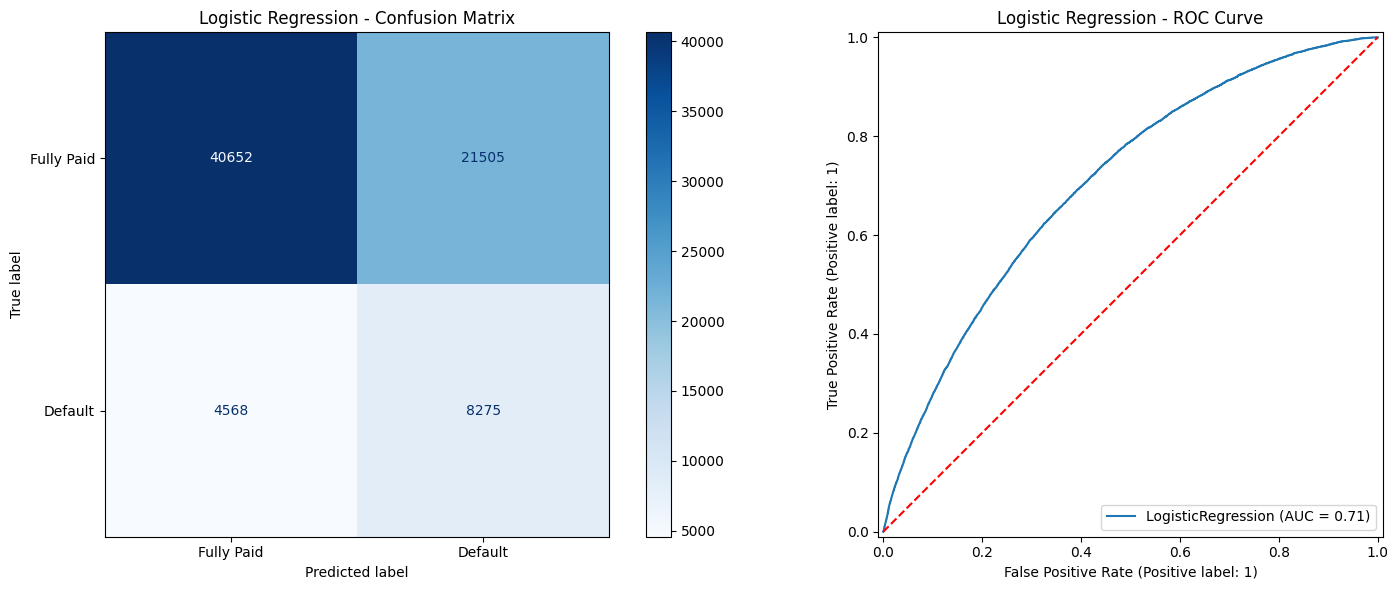


--- Evaluation Report for: Decision Tree ---
Test ROC-AUC: 0.6911
Test PR-AUC:  0.2967  (baseline: 0.1712)
Brier Score:  0.2234
KS Statistic: 0.2834

Classification Report:
                precision    recall  f1-score   support

Fully Paid (0)       0.90      0.63      0.74     62157
   Default (1)       0.27      0.65      0.38     12843

      accuracy                           0.63     75000
     macro avg       0.58      0.64      0.56     75000
  weighted avg       0.79      0.63      0.68     75000



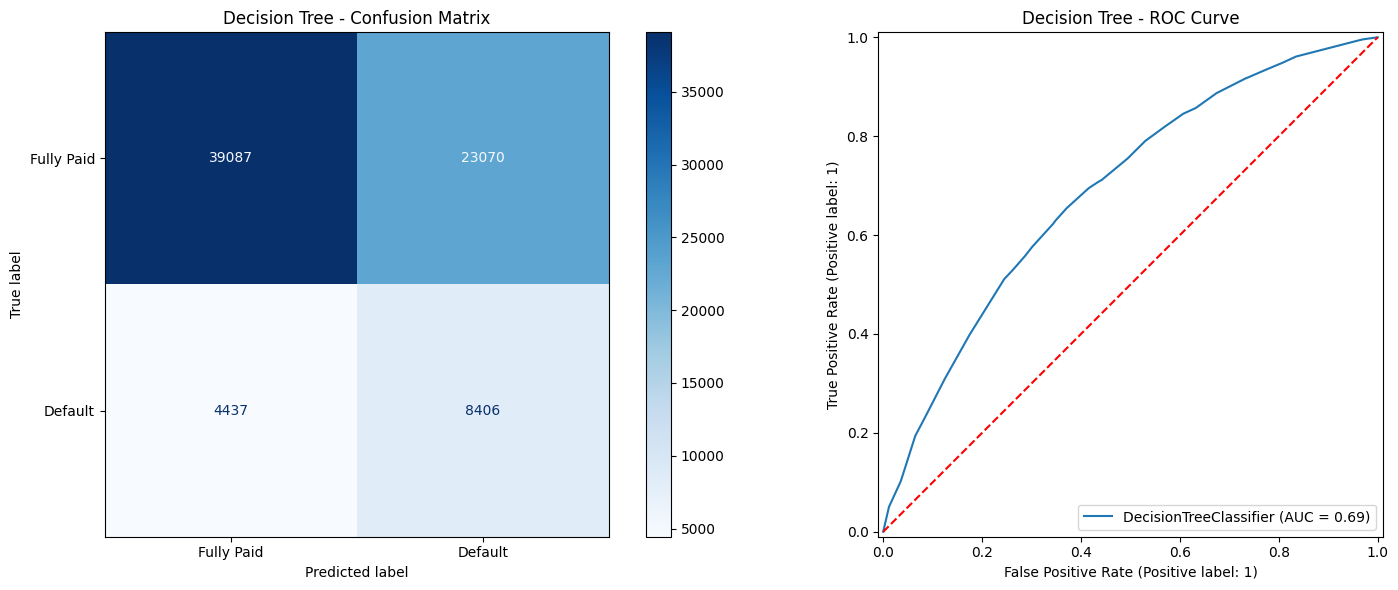


--- Evaluation Report for: Random Forest ---
Test ROC-AUC: 0.7105
Test PR-AUC:  0.3218  (baseline: 0.1712)
Brier Score:  0.1959
KS Statistic: 0.3058

Classification Report:
                precision    recall  f1-score   support

Fully Paid (0)       0.89      0.71      0.79     62157
   Default (1)       0.29      0.59      0.39     12843

      accuracy                           0.69     75000
     macro avg       0.59      0.65      0.59     75000
  weighted avg       0.79      0.69      0.72     75000



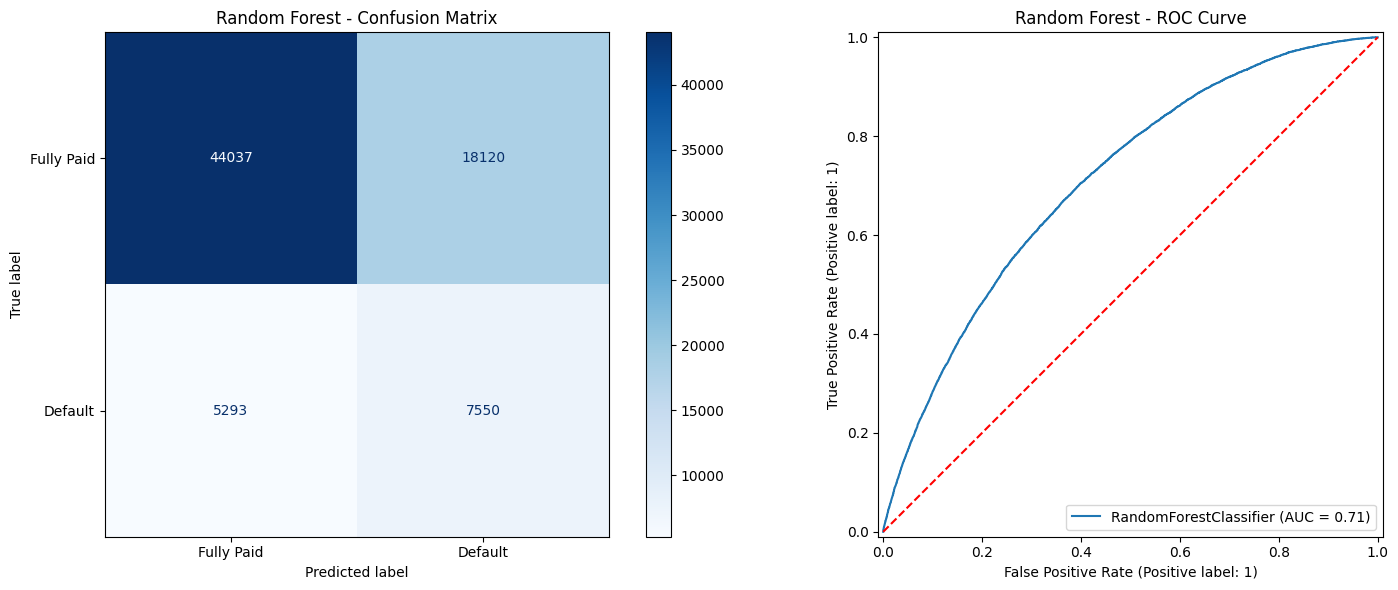


--- Evaluation Report for: LightGBM (Tuned) ---
Test ROC-AUC: 0.7158
Test PR-AUC:  0.3373  (baseline: 0.1712)
Brier Score:  0.2057
KS Statistic: 0.3141

Classification Report:
                precision    recall  f1-score   support

Fully Paid (0)       0.90      0.66      0.76     62157
   Default (1)       0.28      0.66      0.40     12843

      accuracy                           0.66     75000
     macro avg       0.59      0.66      0.58     75000
  weighted avg       0.80      0.66      0.70     75000



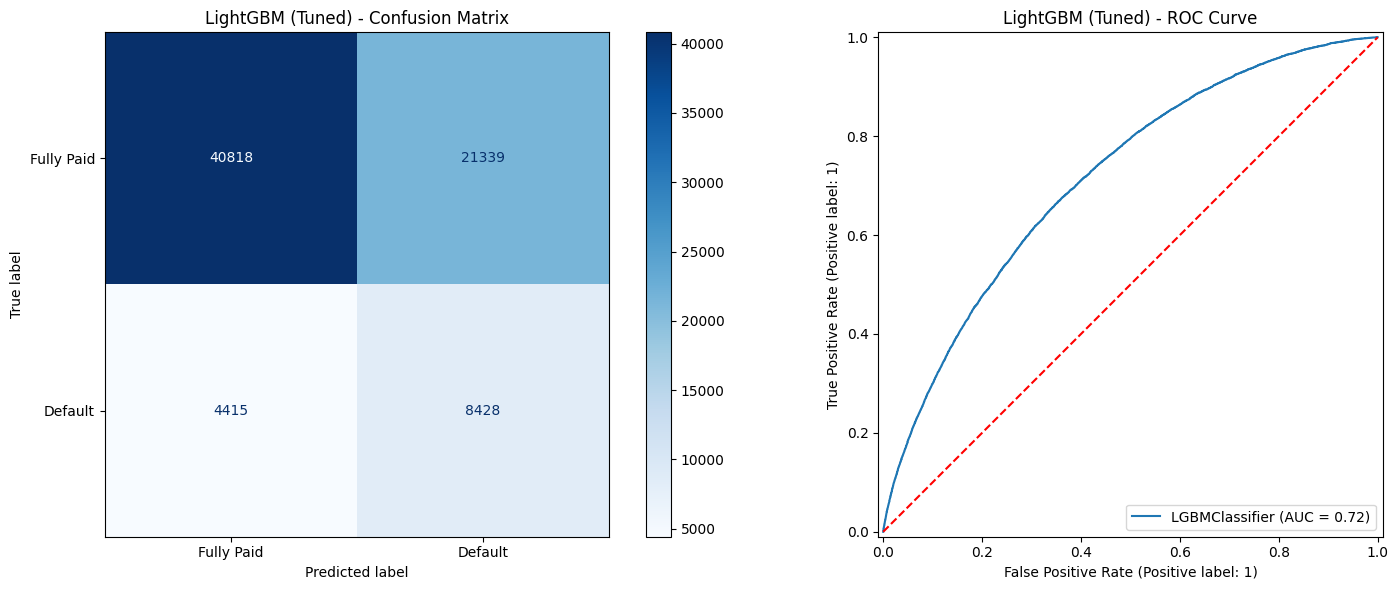


--- Evaluation Report for: CatBoost ---
Test ROC-AUC: 0.7167
Test PR-AUC:  0.3368  (baseline: 0.1712)
Brier Score:  0.2088
KS Statistic: 0.3192

Classification Report:
                precision    recall  f1-score   support

Fully Paid (0)       0.90      0.65      0.76     62157
   Default (1)       0.28      0.67      0.40     12843

      accuracy                           0.65     75000
     macro avg       0.59      0.66      0.58     75000
  weighted avg       0.80      0.65      0.69     75000



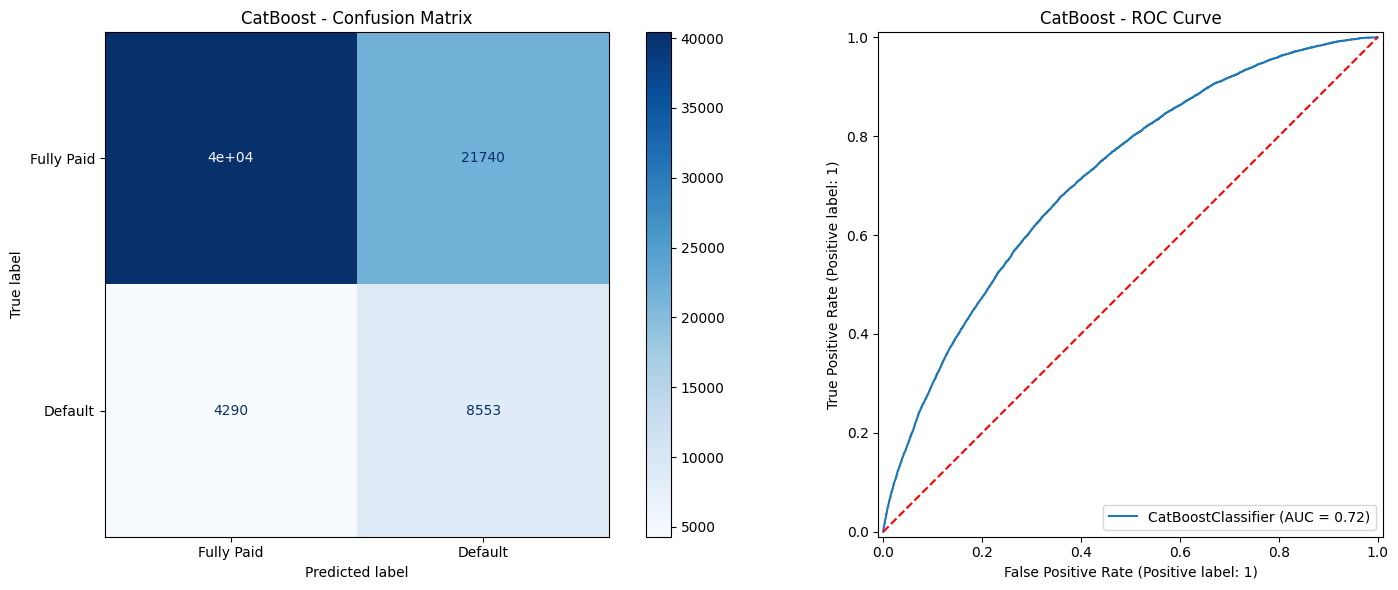



CONSOLIDATED MODEL COMPARISON (Test Set)

Test set base rate: 0.1712  (PR-AUC baseline)

                     ROC-AUC  PR-AUC   Brier      KS
Model                                               
CatBoost              0.7167  0.3368  0.2088  0.3192
LightGBM (Tuned)      0.7158  0.3373  0.2057  0.3141
Random Forest         0.7105  0.3218  0.1959  0.3058
Logistic Regression   0.7056  0.3149  0.2089  0.2992
Decision Tree         0.6911  0.2967  0.2234  0.2834



,ROC-AUC,PR-AUC,Brier,KS
Model,,,,
CatBoost,0.7167,0.3368,0.2088,0.3192
LightGBM (Tuned),0.7158,0.3373,0.2057,0.3141
Random Forest,0.7105,0.3218,0.1959,0.3058
Logistic Regression,0.7056,0.3149,0.2089,0.2992
Decision Tree,0.6911,0.2967,0.2234,0.2834


In [14]:
# --- 7. Model Evaluation (All Models on TEST set — single honest evaluation) ---
print("\n\n--- COMPREHENSIVE MODEL EVALUATION (HONEST TEST SET) ---")
all_metrics.append(evaluate_model(best_lr_model, X_test_processed, y_test, "Logistic Regression"))
all_metrics.append(evaluate_model(best_dt_model, X_test_processed, y_test, "Decision Tree"))
all_metrics.append(evaluate_model(best_rf_model, X_test_processed, y_test, "Random Forest"))
all_metrics.append(evaluate_model(lgbm, X_test_gb, y_test, "LightGBM (Tuned)"))
all_metrics.append(evaluate_model(cat_model, X_test_gb, y_test, "CatBoost"))

# --- Consolidated Model Comparison Table ---
print("\n\n" + "=" * 70)
print("CONSOLIDATED MODEL COMPARISON (Test Set)")
print("=" * 70)
comparison_df = pd.DataFrame(all_metrics).set_index('Model')
comparison_df = comparison_df.sort_values('ROC-AUC', ascending=False)
print(f"\nTest set base rate: {y_test.mean():.4f}  (PR-AUC baseline)")
print()
print(comparison_df.to_string())
print()
comparison_df



--- LGBM FEATURE IMPORTANCE ---


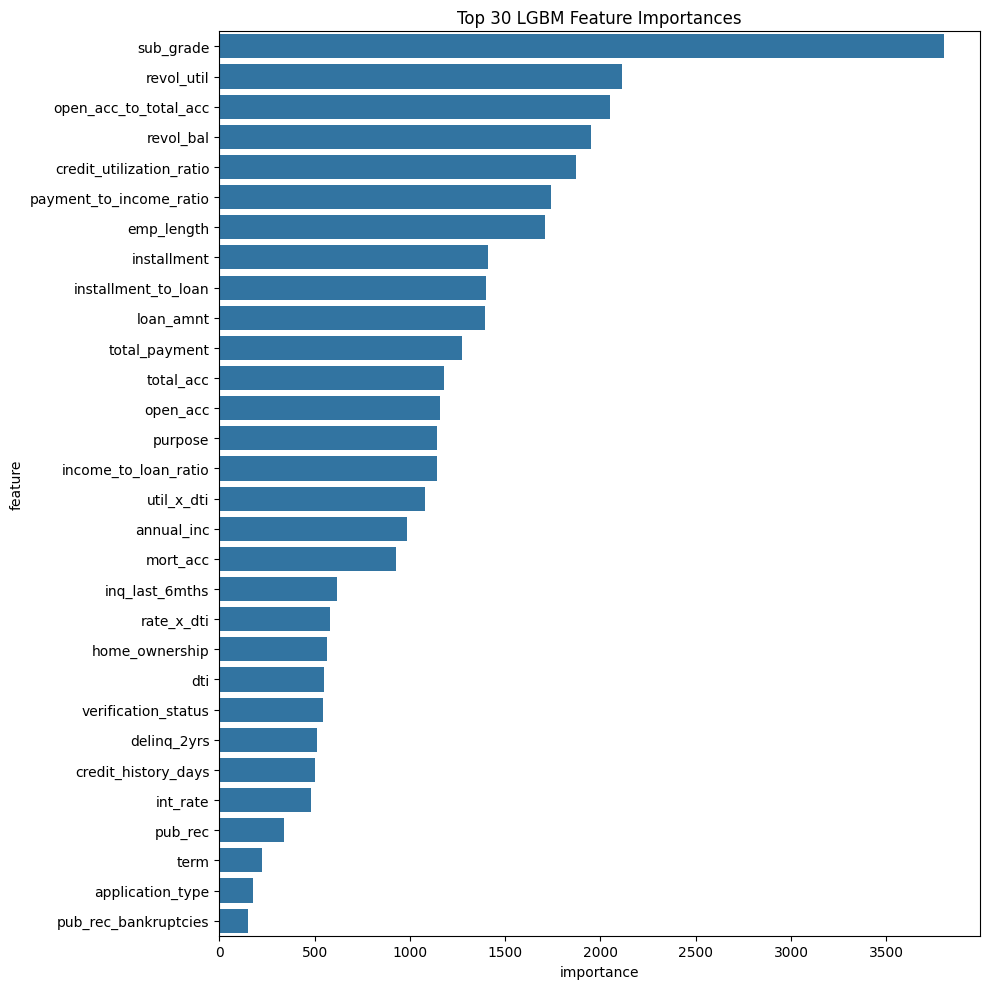

In [15]:
# --- NEW: Feature Importance Plot (from LGBM) ---
print("\n\n--- LGBM FEATURE IMPORTANCE ---")

importances = lgbm.feature_importances_
feature_names = X_train_gb.columns

# Create a DataFrame
feature_importance_df = pd.DataFrame({'feature': feature_names, 'importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='importance', ascending=False)

# Plot top 30
plt.figure(figsize=(10, 10))
sns.barplot(x='importance', y='feature', data=feature_importance_df.head(30))
plt.title('Top 30 LGBM Feature Importances')
plt.tight_layout()
plt.savefig('lgbm_feature_importance.png')
plt.show()



--- CALIBRATION & COST-WEIGHTED THRESHOLD (LGBM) ---
Calibrating LightGBM model on VALIDATION set (isotonic regression)...
Calibration complete.

Cost assumptions: default costs 5×, false reject costs 1×

Cost-optimal threshold: 0.1655  (expected loss: 0.6136)
F1-optimal threshold:  0.2353  (F1: 0.4750)


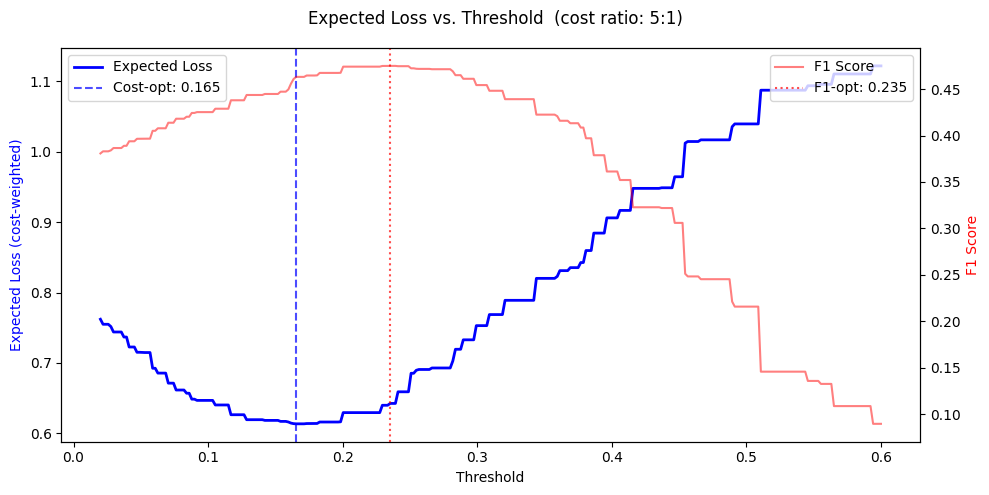


--- Calibration Reliability Curve ---


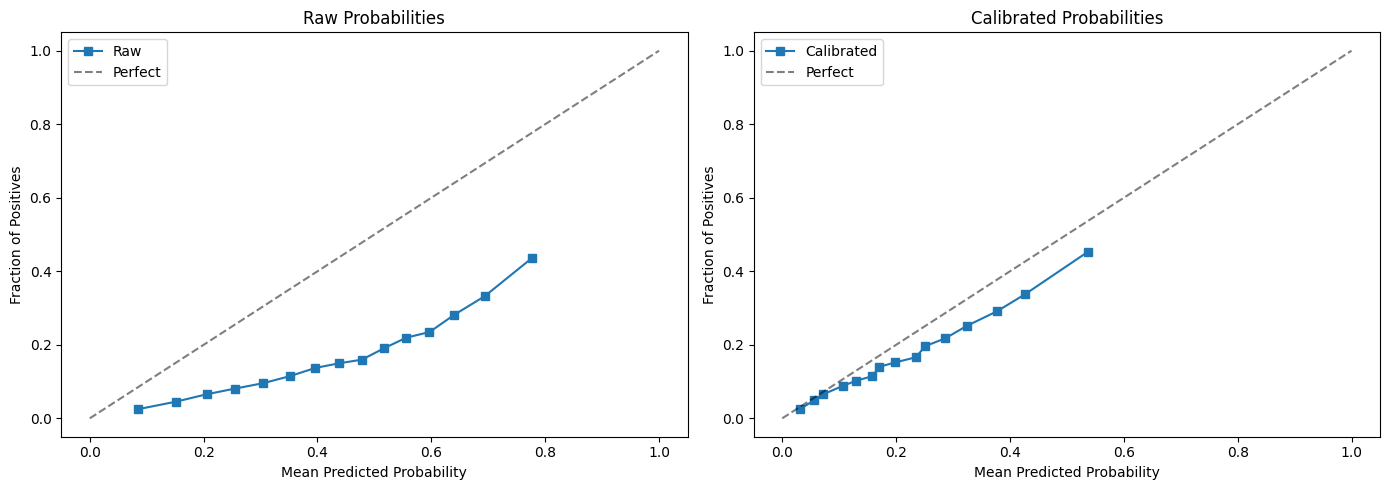


--- Bootstrap 95% CI on Test AUC ---
Test AUC: 0.7156  (95% CI: [0.7106, 0.7202])

--- FINAL EVALUATION ON HELD-OUT TEST SET (threshold=0.1655) ---
Honest Test AUC: 0.7156

--- Classification Report with Cost-Weighted Threshold (Test Set) ---
                precision    recall  f1-score   support

Fully Paid (0)       0.92      0.50      0.65     62157
   Default (1)       0.25      0.79      0.38     12843

      accuracy                           0.55     75000
     macro avg       0.58      0.65      0.52     75000
  weighted avg       0.81      0.55      0.61     75000



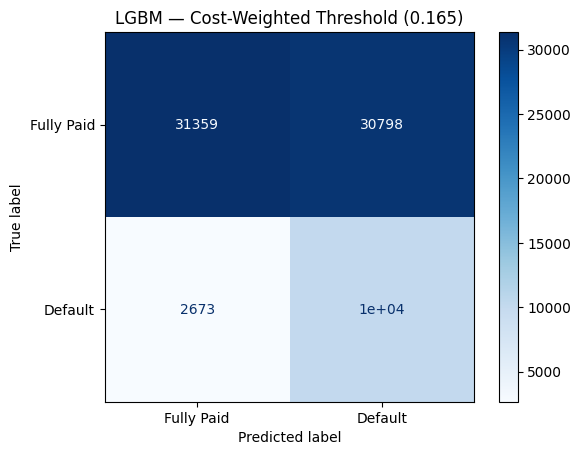

In [16]:
# --- 8. Calibration, Cost-Weighted Threshold & Bootstrap CI ---
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve

print("\n\n--- CALIBRATION & COST-WEIGHTED THRESHOLD (LGBM) ---")

# Step 1: Calibrate on validation set
print("Calibrating LightGBM model on VALIDATION set (isotonic regression)...")
raw_val_proba = lgbm.predict_proba(X_val_gb)[:, 1]
iso_calibrator = IsotonicRegression(out_of_bounds='clip')
iso_calibrator.fit(raw_val_proba, y_val)
cal_val_proba = iso_calibrator.transform(raw_val_proba)
print("Calibration complete.")

# Step 2: Cost-weighted threshold selection
# A funded default is far more costly than rejecting a good loan.
# Cost ratio: cost_default / cost_reject — typically 3–10× in lending.
COST_DEFAULT = 5    # relative cost of funding a loan that defaults
COST_REJECT  = 1    # relative cost of rejecting a good loan

print(f"\nCost assumptions: default costs {COST_DEFAULT}×, false reject costs {COST_REJECT}×")

thresholds_grid = np.linspace(0.02, 0.60, 300)
expected_losses = []
f1_scores_grid = []

for t in thresholds_grid:
    preds = (cal_val_proba >= t).astype(int)
    fn = ((preds == 0) & (y_val == 1)).sum()  # funded defaults (miss)
    fp = ((preds == 1) & (y_val == 0)).sum()  # rejected good loans (false alarm)
    loss = COST_DEFAULT * fn + COST_REJECT * fp
    expected_losses.append(loss / len(y_val))
    f1_scores_grid.append(f1_score(y_val, preds, zero_division=0))

expected_losses = np.array(expected_losses)
f1_scores_grid = np.array(f1_scores_grid)

best_cost_idx = np.argmin(expected_losses)
best_threshold = thresholds_grid[best_cost_idx]
best_f1_idx = np.argmax(f1_scores_grid)

print(f"\nCost-optimal threshold: {best_threshold:.4f}  (expected loss: {expected_losses[best_cost_idx]:.4f})")
print(f"F1-optimal threshold:  {thresholds_grid[best_f1_idx]:.4f}  (F1: {f1_scores_grid[best_f1_idx]:.4f})")

# Plot expected loss vs threshold
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(thresholds_grid, expected_losses, 'b-', linewidth=2, label='Expected Loss')
ax1.axvline(x=best_threshold, color='blue', linestyle='--', alpha=0.7, label=f'Cost-opt: {best_threshold:.3f}')
ax1.set_xlabel('Threshold')
ax1.set_ylabel('Expected Loss (cost-weighted)', color='blue')
ax2 = ax1.twinx()
ax2.plot(thresholds_grid, f1_scores_grid, 'r-', alpha=0.5, label='F1 Score')
ax2.axvline(x=thresholds_grid[best_f1_idx], color='red', linestyle=':', alpha=0.7, label=f'F1-opt: {thresholds_grid[best_f1_idx]:.3f}')
ax2.set_ylabel('F1 Score', color='red')
fig.suptitle(f'Expected Loss vs. Threshold  (cost ratio: {COST_DEFAULT}:{COST_REJECT})')
ax1.legend(loc='upper left'); ax2.legend(loc='upper right')
plt.tight_layout()
plt.savefig('cost_threshold_analysis.png')
plt.show()

# Step 3: Calibration reliability curve
print("\n--- Calibration Reliability Curve ---")
raw_test_proba = lgbm.predict_proba(X_test_gb)[:, 1]
cal_test_proba = iso_calibrator.transform(raw_test_proba)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (probas, label) in zip(axes, [(raw_test_proba, 'Raw'), (cal_test_proba, 'Calibrated')]):
    fraction_pos, mean_pred = calibration_curve(y_test, probas, n_bins=15, strategy='quantile')
    ax.plot(mean_pred, fraction_pos, 's-', label=label)
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Perfect')
    ax.set_xlabel('Mean Predicted Probability')
    ax.set_ylabel('Fraction of Positives')
    ax.set_title(f'{label} Probabilities')
    ax.legend()
plt.tight_layout()
plt.savefig('calibration_curve.png')
plt.show()

# Step 4: Bootstrap confidence interval on test AUC
print("\n--- Bootstrap 95% CI on Test AUC ---")
n_boot = 1000
rng = np.random.RandomState(42)
boot_aucs = []
for _ in range(n_boot):
    idx = rng.choice(len(y_test), size=len(y_test), replace=True)
    if len(np.unique(y_test.values[idx])) < 2:
        continue
    boot_aucs.append(roc_auc_score(y_test.values[idx], cal_test_proba[idx]))
boot_aucs = np.array(boot_aucs)
ci_lo, ci_hi = np.percentile(boot_aucs, [2.5, 97.5])
point_auc = roc_auc_score(y_test, cal_test_proba)
print(f"Test AUC: {point_auc:.4f}  (95% CI: [{ci_lo:.4f}, {ci_hi:.4f}])")

# Step 5: Final honest evaluation with cost-optimal threshold
print(f"\n--- FINAL EVALUATION ON HELD-OUT TEST SET (threshold={best_threshold:.4f}) ---")
test_auc = roc_auc_score(y_test, cal_test_proba)
print(f"Honest Test AUC: {test_auc:.4f}")

y_pred_tuned = (cal_test_proba >= best_threshold).astype(int)
print(f"\n--- Classification Report with Cost-Weighted Threshold (Test Set) ---")
print(classification_report(y_test, y_pred_tuned, target_names=['Fully Paid (0)', 'Default (1)']))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_tuned,
                                      cmap='Blues',
                                      display_labels=['Fully Paid', 'Default'])
plt.title(f"LGBM — Cost-Weighted Threshold ({best_threshold:.3f})")
plt.savefig('evaluation_lgbm_tuned.png')
plt.show()



--- MODEL EXPLAINABILITY (SHAP) ---


Creating SHAP explainer...
Calculating SHAP values for a sample...


c:\Users\amans\Desktop\LC FODS PROJECT\lendingclub\Lib\site-packages\shap\explainers\_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


SHAP Global Feature Importance (Bar Plot)


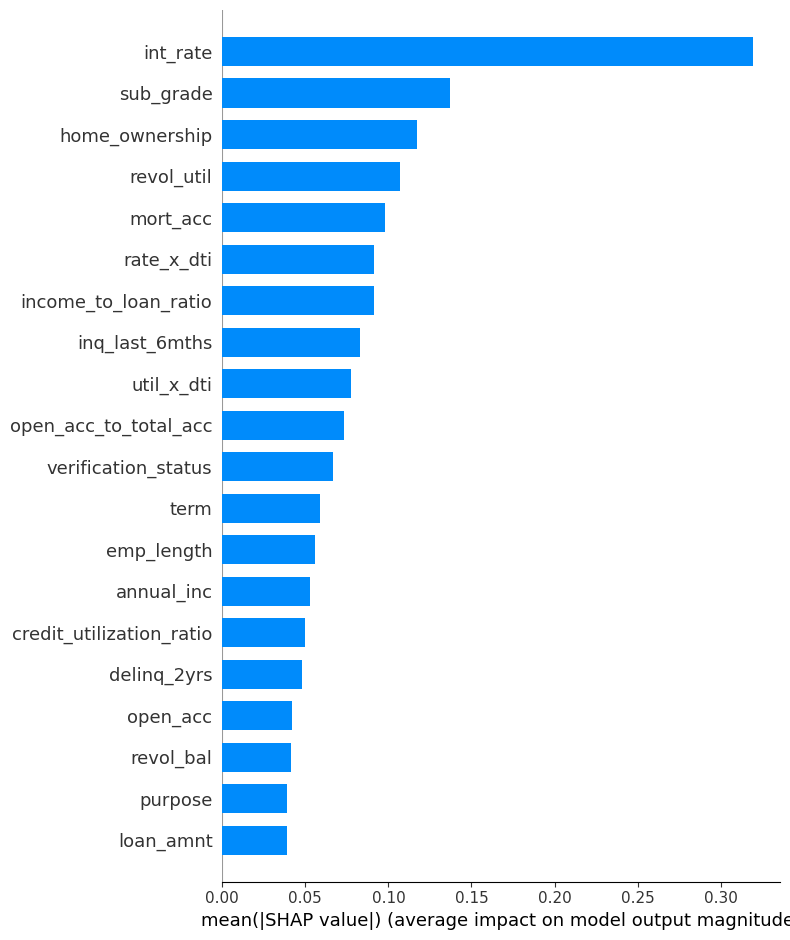


SHAP Global Feature Importance (Summary/Dot Plot)


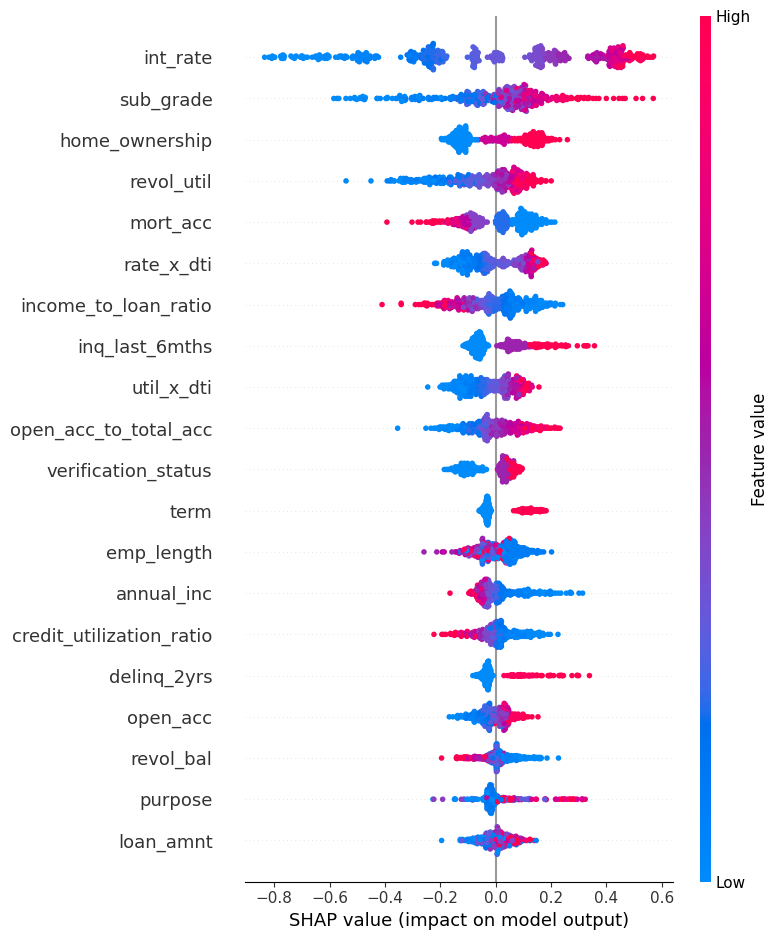


SHAP Local Explanation (Waterfall Plot for first test sample)


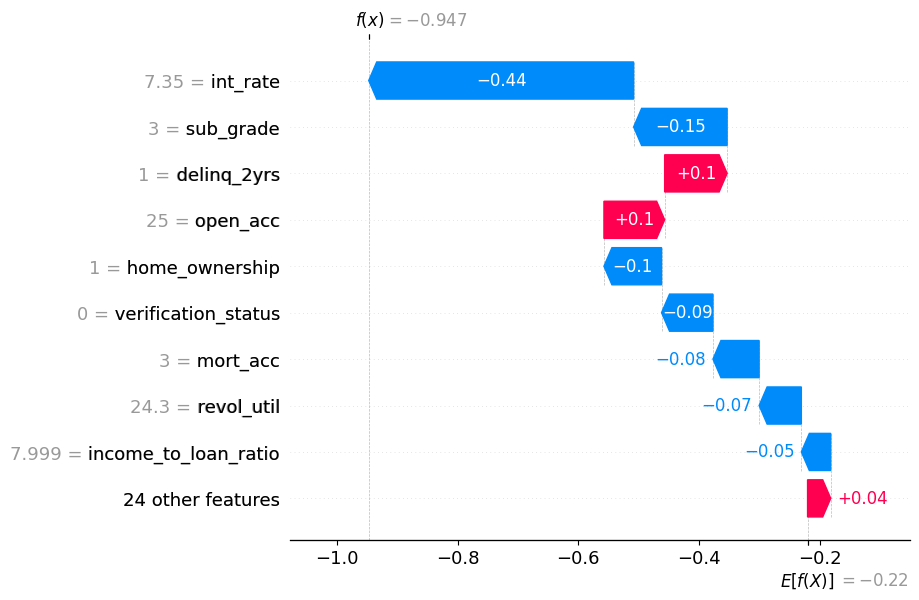

In [17]:
# --- 9. Model Explainability (SHAP) ---
print("\n\n--- MODEL EXPLAINABILITY (SHAP) ---")
try:
    shap.initjs()
    print("Creating SHAP explainer...")
    explainer = shap.TreeExplainer(lgbm) # Use the uncalibrated model
    
    print("Calculating SHAP values for a sample...")
    # SHAP can be slow, so we sample the test set
    X_test_sample = X_test_gb.sample(n=min(500, len(X_test_gb)), random_state=42)
    
    # Use .shap_values() which is more explicit for binary classification
    shap_values_list = explainer.shap_values(X_test_sample)
    
    # Check if we got a list (binary classification) or a single array
    if isinstance(shap_values_list, list) and len(shap_values_list) == 2:
        shap_values_class_1 = shap_values_list[1] # Values for the positive class (1)
    else:
        shap_values_class_1 = shap_values_list # Assume it's already for the positive class
        
    # Check if expected_value is a list/array or a single scalar
    if isinstance(explainer.expected_value, (list, np.ndarray)):
        expected_value_class_1 = explainer.expected_value[1] # Base value for the positive class (1)
    else:
        expected_value_class_1 = explainer.expected_value # It's a single scalar value

    print("SHAP Global Feature Importance (Bar Plot)")
    # Use the shap_values_class_1 array directly
    shap.summary_plot(shap_values_class_1, X_test_sample, plot_type="bar", show=False)
    plt.savefig('shap_bar_plot.png')
    plt.show()

    print("\nSHAP Global Feature Importance (Summary/Dot Plot)")
    shap.summary_plot(shap_values_class_1, X_test_sample, show=False)
    plt.savefig('shap_summary_plot.png')
    plt.show()

    print("\nSHAP Local Explanation (Waterfall Plot for first test sample)")
    # Create the Explanation object correctly
    shap.waterfall_plot(shap.Explanation(
        values=shap_values_class_1[0,:],
        base_values=expected_value_class_1,
        data=X_test_sample.iloc[0,:],
        feature_names=X_test_sample.columns.tolist()
    ), show=False)
    plt.savefig('shap_waterfall_plot.png')
    plt.show()

except Exception as e:
    print(f"SHAP visualization failed. This can happen in some environments. Error: {e}")

In [18]:
# --- 10. Deployment Artifacts ---
# SHAP TreeExplainer is rebuilt at runtime in app.py — no need to pickle it.
# Atomic writes prevent null-byte corruption when overwriting larger files.
import tempfile, shutil

print("\n\n--- SAVING DEPLOYMENT ARTIFACTS ---")

def atomic_dump(obj, path):
    """Write to a temp file, then atomically replace — prevents null-byte corruption
    when overwriting a larger file in-place."""
    dir_name = os.path.dirname(os.path.abspath(path))
    fd, tmp = tempfile.mkstemp(dir=dir_name, suffix='.tmp')
    os.close(fd)
    try:
        joblib.dump(obj, tmp)
        shutil.move(tmp, path)
    except:
        if os.path.exists(tmp):
            os.remove(tmp)
        raise

print(f"Saving optimal threshold: {best_threshold:.4f}")

artifacts = {
    'model': lgbm,
    'iso_calibrator': iso_calibrator,
    'imputation_values': imputation_values,
    'categorical_features': categorical_features_for_boost,
    'feature_columns': X_train_gb.columns.tolist(),
    'label_encoders': label_encoders,
    'optimal_threshold': best_threshold
}
atomic_dump(artifacts, 'model_artifacts.joblib')

# Individual files for backward compatibility
atomic_dump(lgbm, 'lgbm_model.joblib')
atomic_dump(iso_calibrator, 'iso_calibrator.joblib')
atomic_dump(imputation_values, 'imputation_values.joblib')
atomic_dump(categorical_features_for_boost, 'categorical_features.joblib')
atomic_dump(X_train_gb.columns.tolist(), 'feature_columns.joblib')
atomic_dump(label_encoders, 'label_encoders.joblib')

# Clean up orphan explainer from previous runs (no longer needed)
if os.path.exists('shap_explainer.joblib'):
    os.remove('shap_explainer.joblib')
    print("Deleted orphan shap_explainer.joblib (no longer referenced)")

print("\nAll artifacts saved to disk (bundled + individual files)")
print(f"Feature columns saved: {X_train_gb.columns.tolist()}")

# Verify sizes are reasonable (no trailing junk)
for f in ['model_artifacts.joblib', 'lgbm_model.joblib', 'iso_calibrator.joblib',
          'imputation_values.joblib', 'categorical_features.joblib',
          'feature_columns.joblib', 'label_encoders.joblib']:
    sz = os.path.getsize(f)
    print(f"  {f}: {sz:,} bytes")



--- SAVING DEPLOYMENT ARTIFACTS ---
Saving optimal threshold: 0.1655
Deleted orphan shap_explainer.joblib (no longer referenced)

All artifacts saved to disk (bundled + individual files)
Feature columns saved: ['loan_amnt', 'term', 'int_rate', 'installment', 'sub_grade', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'purpose', 'dti', 'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'application_type', 'mort_acc', 'pub_rec_bankruptcies', 'tax_liens', 'income_to_loan_ratio', 'credit_utilization_ratio', 'credit_history_days', 'term_in_months', 'total_payment', 'payment_to_income_ratio', 'open_acc_to_total_acc', 'util_x_dti', 'rate_x_dti', 'installment_to_loan']
  model_artifacts.joblib: 3,894,840 bytes
  lgbm_model.joblib: 3,887,412 bytes
  iso_calibrator.joblib: 3,015 bytes
  imputation_values.joblib: 1,136 bytes
  categorical_features.joblib: 138 bytes
  feature_columns.joblib: 532 bytes
  lab